# Reviewer analyses from a server snapshot

Run this notebook locally after copying a real-data server snapshot (set `IIVV_SNAPSHOT` to its path). It reads cohort/quality/repeatability reports and verified completed fold checkpoints. **No model fitting, threshold tuning, bootstrap recomputation, significance testing or manuscript import occurs.**

Section 6 prints descriptive classifier metrics and plots ROC curves and confusion matrices from the saved outer-test predictions. Missing folds are never imputed. Results based on copied completed folds can be selected by computation time and are **preliminary**, not final pooled performance estimates. A complete copied task is still subject to the final server-run verification. Final analyses remain in Figures-and-Tables.ipynb and manuscript/Reviewer-Evidence.ipynb.

Derived tables/figures are saved separately under `results/revision-snapshot-analysis/<snapshot-hash>/`. Patient identifiers are present in the copied study artifacts.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_revision.py").is_file()
)
SNAPSHOT = (
    ROOT / os.environ.get("IIVV_SNAPSHOT", "results/revision-server-snapshot-20261027-081917")
).resolve()
INPUTS = {}


def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def tracked(path):
    path = Path(path).resolve()
    if not path.is_relative_to(SNAPSHOT):
        raise ValueError(f"Input is outside the copied snapshot: {path}")
    INPUTS[str(path.relative_to(SNAPSHOT))] = sha(path)
    return path


def jread(path):
    return json.loads(tracked(path).read_text())


def cread(path, **kwargs):
    path = tracked(path)
    try:
        return pd.read_csv(path, **kwargs)
    except pd.errors.EmptyDataError:
        return pd.DataFrame()


manifest = jread(SNAPSHOT / "run_manifest.json")
if manifest.get("synthetic") or not manifest.get("input_hashes"):
    raise ValueError(
        "A real-data snapshot with a recorded input inventory is required."
    )
cfg = manifest["config"]
display(
    {
        "snapshot": str(SNAPSHOT),
        "recorded_run_status": manifest["status"],
        "input_summary": manifest.get("input_summary"),
        "folds": cfg["outer_folds"],
        "inner_folds": cfg["inner_folds"],
        "outer_partitions": cfg["outer_repeats"],
    }
)
display(
    Markdown(
        "**Snapshot analysis only. The manifest status is preserved; this notebook does not certify run completion.**"
    )
)

{'snapshot': '/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-server-snapshot-20261027-081917',
 'recorded_run_status': 'running',
 'input_summary': {'n_sites': 276,
  'n_patients': 100,
  'n_frequencies': 31,
  'n_patterns': 7728,
  'complex_available': True,
  'unmapped_pathologies': {'leukoplakia': 2,
   'basaloid scc': 1,
   'high-grade adenocarcinoma': 1}},
 'folds': 5,
 'inner_folds': 4,
 'outer_partitions': 1}

**Snapshot analysis only. The manifest status is preserved; this notebook does not certify run completion.**

## 1. Verify completed folds — R1 C1, C7–8, C21; R3 C1

Only folders with complete.json are used. Every listed artifact is checked against its completion hash. A mismatch stops analysis: recopy that complete folder. Incomplete folders are ignored. This inventory checks copied files, not the original server MAT/NPZ inputs or the validity of an unfinished experiment.


In [2]:
execution = jread(SNAPSHOT / "parallel_execution.json")
expected = {(row["task"], tuple(row["key"])) for row in execution["fold_order"]}
known_sources = [manifest["source_hashes"]]
for parent in SNAPSHOT.glob("resume-parent-*.json"):
    known_sources.append(jread(parent)["source_hashes"])
FOLDS, inventory, task_inventories = [], [], {}
required = {
    "splits.json",
    "selections.json",
    "candidate_failures.json",
    "outer_predictions.csv",
    "inner_search.csv",
    "task_inclusion.csv",
    "task_label_audit.csv",
    "classes.json",
}
for marker_path in sorted((SNAPSHOT / "fold-checkpoints").glob("*/*/complete.json")):
    marker = jread(marker_path)
    folder = marker_path.parent
    identity = (marker["task"], tuple(marker["fold_key"]))
    if identity not in expected or marker["task"] != folder.parent.name:
        raise ValueError(f"Unexpected fold identity: {folder}")
    if not required <= set(marker["artifacts"]):
        raise ValueError(f"Incomplete checkpoint inventory: {folder}")
    if marker.get("source_version", {}).get("hashes") not in known_sources:
        raise ValueError(
            "Unknown checkpoint source version; copy its matching resume-parent manifest."
        )
    for relative, recorded_hash in marker["artifacts"].items():
        path = (folder / relative).resolve()
        if not path.is_relative_to(folder.resolve()) or sha(path) != recorded_hash:
            raise ValueError(
                f"Checkpoint hash mismatch: {path}; recopy this completed fold."
            )
        tracked(path)
    previous = task_inventories.setdefault(
        marker["task"], marker["artifacts"]["task_inclusion.csv"]
    )
    if previous != marker["artifacts"]["task_inclusion.csv"]:
        raise ValueError("Different task inclusion inventories in one snapshot.")
    FOLDS.append((folder, marker))
    inventory.append(
        {
            "task": marker["task"],
            "repeat": marker["fold_key"][0],
            "outer_fold": marker["fold_key"][1],
            "evaluation": marker["fold_key"][2],
            "elapsed_hours": marker["elapsed_seconds"] / 3600,
            "checkpoint": str(folder),
        }
    )
if len({(m["task"], tuple(m["fold_key"])) for _, m in FOLDS}) != len(FOLDS):
    raise ValueError("Duplicate completed fold identities.")
SNAPSHOT_HASH = hashlib.sha256(json.dumps(INPUTS, sort_keys=True).encode()).hexdigest()
OUT = ROOT / "results/revision-snapshot-analysis" / SNAPSHOT_HASH[:12]
OUT.mkdir(parents=True, exist_ok=True)


def table(frame, name):
    if not isinstance(frame, pd.DataFrame):
        frame = pd.DataFrame(frame)
    frame.to_csv(OUT / (name + ".csv"), index=False)
    display(Markdown(f"**{name}** — {len(frame)} rows; the CSV contains all rows."))
    display(frame.head(30))
    return frame


def figure(fig, name):
    for suffix in ("png", "pdf"):
        fig.savefig(OUT / (name + "." + suffix), dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


table(
    pd.DataFrame(
        inventory,
        columns=[
            "task",
            "repeat",
            "outer_fold",
            "evaluation",
            "elapsed_hours",
            "checkpoint",
        ],
    ),
    "copied-completed-folds",
)
display(
    {
        "completed_folds_copied": len(FOLDS),
        "scheduled_folds": len(expected),
        "derived_output_directory": str(OUT),
    }
)

**copied-completed-folds** — 18 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,elapsed_hours,checkpoint
0,MC,0,0,nested_cv,65.512543,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
1,MC,0,1,nested_cv,68.795273,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
2,MC,0,3,nested_cv,135.503085,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
3,MC,0,4,nested_cv,62.554196,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
4,cancer_vs_lr_hr,0,0,nested_cv,7.621610,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
5,cancer_vs_lr_hr,0,1,nested_cv,98.425436,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
6,cancer_vs_lr_hr,0,2,nested_cv,35.739067,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
7,cancer_vs_lr_hr,0,3,nested_cv,18.298971,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
8,cancer_vs_lr_hr,0,4,nested_cv,33.063273,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...
9,healthy_vs_cancer,0,0,nested_cv,45.604751,/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Ev...


{'completed_folds_copied': 18,
 'scheduled_folds': 20,
 'derived_output_directory': '/home/jacob/Schreibtisch/Uni/Forschung/IIVV-Evaluation/results/revision-snapshot-analysis/663a95778569'}

## 2. Cohort, labels and available demographics — R1 C10–14, M6; R2 C3

Samples are measurement sites. A patient can contribute multiple tissue classes or locations; do not sum patient counts across such strata. These tables describe the full saved source audit, including unmapped diagnoses, before task-specific exclusion. Missing demographic values are reported rather than imputed.


**source-pathology-counts** — 5 rows; the CSV contains all rows.

,pathology,n_samples,n_patients
0,Cancer,96,70
1,Healthy,100,95
2,High-grade dysplasia,32,21
3,Non-malignant,44,28
4,Unmapped / excluded,4,4


**raw-pathology-counts** — 13 rows; the CSV contains all rows.

,pathology,raw_pathology,n_samples,n_patients
0,Cancer,invasive carcinoma,96,70
1,Healthy,healthy,100,95
2,High-grade dysplasia,cis,5,4
3,High-grade dysplasia,high grade dysplasia,2,2
4,High-grade dysplasia,high-grade dysplasia,8,7
5,High-grade dysplasia,high-grade dysplasia /cis,1,1
6,High-grade dysplasia,high-grade dysplasia/ cis,8,4
7,High-grade dysplasia,moderate dysplasia,8,7
8,Non-malignant,benign,33,20
9,Non-malignant,mild dysplasia,11,8


**samples-per-patient** — 8 rows; the CSV contains all rows.

...

,variable,available
0,prior_radiation,True
1,location,True
2,prior_surgery,True
3,age,False
4,sex,False
5,smoking,False
6,alcohol,False
7,inflammation,False
8,treatment_history,False
9,contact_pressure,False


**available-categorical-demographics** — 87 rows; the CSV contains all rows.

,variable,pathology,value,n_samples,n_patients
0,prior_radiation,Cancer,<missing>,11,6
1,prior_radiation,Cancer,No,77,58
2,prior_radiation,Cancer,Yes,8,6
3,prior_radiation,Healthy,<missing>,8,8
4,prior_radiation,Healthy,No,82,77
5,prior_radiation,Healthy,Yes,10,10
6,prior_radiation,High-grade dysplasia,No,27,18
7,prior_radiation,High-grade dysplasia,Yes,5,3
8,prior_radiation,Non-malignant,<missing>,12,5
9,prior_radiation,Non-malignant,No,29,21


**pathology-by-location** — 5 rows; the CSV contains all rows.

location,pathology,<missing>,alveolar ridge,anterior tongue,base tongue,buccal margin,buccal mucosa,floor of mouth,floor of the mouth,gingival mucosa,...,retromolar trigone / palate,right anterior tongue,right buccal mucosa,right retromolar trigone,right soft palate,soft palate,tonsil,tonsillar pillar,upper lip,ventral tongue
0,Cancer,0,3,0,9,0,3,1,15,2,...,0,0,0,0,0,1,16,0,1,1
1,Healthy,1,0,0,4,0,34,0,5,2,...,0,1,2,1,1,6,12,1,0,0
2,High-grade dysplasia,0,0,0,0,0,3,0,3,0,...,0,0,0,0,0,0,1,1,0,0
3,Non-malignant,0,0,1,2,1,4,0,3,0,...,0,0,0,0,0,2,1,0,0,2
4,Unmapped / excluded,0,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,1,0,0,0


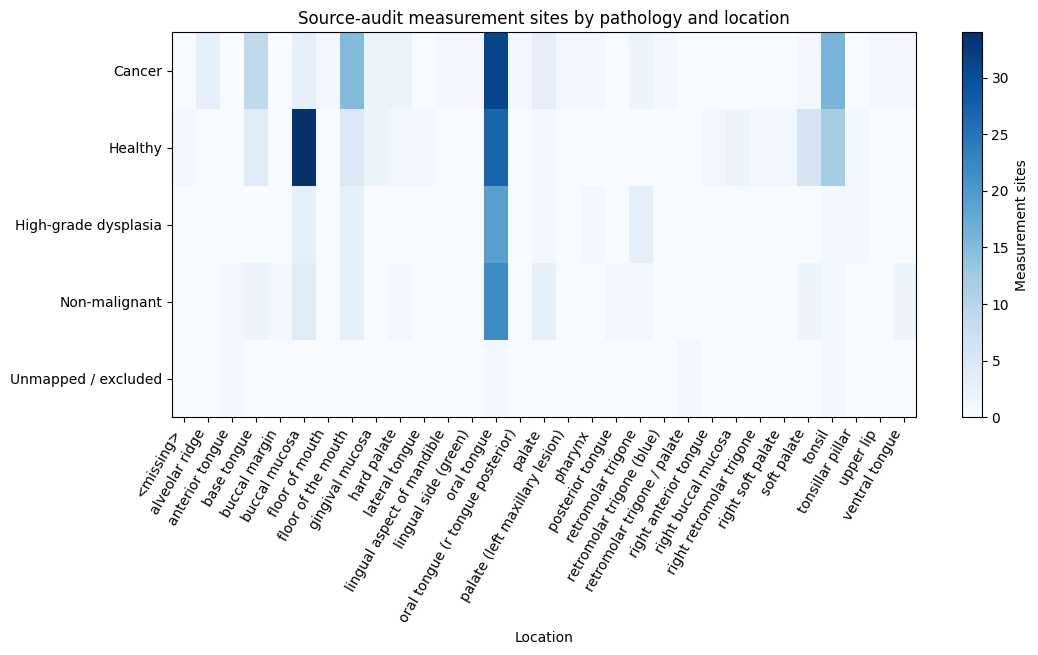

In [3]:
sites = cread(
    SNAPSHOT / "quality/site_inclusion_audit.csv",
    dtype={"patient_id": str, "sample_id": str, "site_id": str},
)
if not sites.sample_id.is_unique:
    raise ValueError("Duplicate source-audit sample identifiers.")
cohort = sites.assign(pathology=sites.pathology.fillna("Unmapped / excluded"))
counts = (
    cohort.groupby("pathology", dropna=False)
    .agg(n_samples=("sample_id", "size"), n_patients=("patient_id", "nunique"))
    .reset_index()
)
table(counts, "source-pathology-counts")
raw_counts = (
    cohort.groupby(["pathology", "raw_pathology"], dropna=False)
    .agg(n_samples=("sample_id", "size"), n_patients=("patient_id", "nunique"))
    .reset_index()
)
table(raw_counts, "raw-pathology-counts")
sizes = cohort.groupby("patient_id").size()
table(
    sizes.value_counts()
    .sort_index()
    .rename_axis("samples_per_patient")
    .reset_index(name="n_patients"),
    "samples-per-patient",
)
clinical = jread(SNAPSHOT / "quality/clinical_metadata_status.json")
table(
    [{"variable": col, "available": True} for col in clinical["available"]]
    + [{"variable": col, "available": False} for col in clinical["missing"]],
    "clinical-field-availability",
)
demographics = []
for column in clinical["available"]:
    if column not in cohort:
        continue
    if pd.api.types.is_numeric_dtype(cohort[column]):
        continue  # actual per-patient numeric distributions are not guessed from categorical reports
    view = cohort.assign(value=cohort[column].fillna("<missing>").astype(str))
    for (pathology, value), group in view.groupby(["pathology", "value"], dropna=False):
        demographics.append(
            {
                "variable": column,
                "pathology": pathology,
                "value": value,
                "n_samples": len(group),
                "n_patients": group.patient_id.nunique(),
            }
        )
table(demographics, "available-categorical-demographics")
if "location" in cohort:
    anatomy = pd.crosstab(cohort.pathology, cohort.location.fillna("<missing>"))
    table(anatomy.reset_index(), "pathology-by-location")
    fig, ax = plt.subplots(figsize=(12, 5))
    image = ax.imshow(anatomy.to_numpy(), aspect="auto", cmap="Blues")
    ax.set_xticks(range(len(anatomy.columns)), anatomy.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(anatomy.index)), anatomy.index)
    ax.set(
        title="Source-audit measurement sites by pathology and location",
        xlabel="Location",
    )
    fig.colorbar(image, ax=ax, label="Measurement sites")
    figure(fig, "pathology-by-location")

## 3. Signal-quality filtering and class/location bias — R1 C2–5, C13–14

These are saved quality audits, not classifier performance. The strict cutoff rule is missing_percent < cutoff; 100.000001 includes every valid 0–100 score. Retained-site percentages and demographic composition cannot establish that a cutoff is diagnostically safe. Existing association p values are displayed as recorded; no statistical test is rerun.


**quality-retention-by-class** — 20 rows; the CSV contains all rows.

,cutoff,class_name,n_total_sites,n_retained_sites,n_total_patients,n_retained_patients,retained_site_percent
0,40.000000,Cancer,96,96,70,70,100.000000
1,40.000000,Healthy,100,75,95,74,75.000000
2,40.000000,High-grade dysplasia,32,26,21,17,81.250000
3,40.000000,Non-malignant,44,40,28,26,90.909091
4,40.000000,Unmapped / excluded,4,2,4,2,50.000000
5,60.000000,Cancer,96,96,70,70,100.000000
6,60.000000,Healthy,100,90,95,88,90.000000
7,60.000000,High-grade dysplasia,32,29,21,19,90.625000
8,60.000000,Non-malignant,44,41,28,27,93.181818
9,60.000000,Unmapped / excluded,4,4,4,4,100.000000


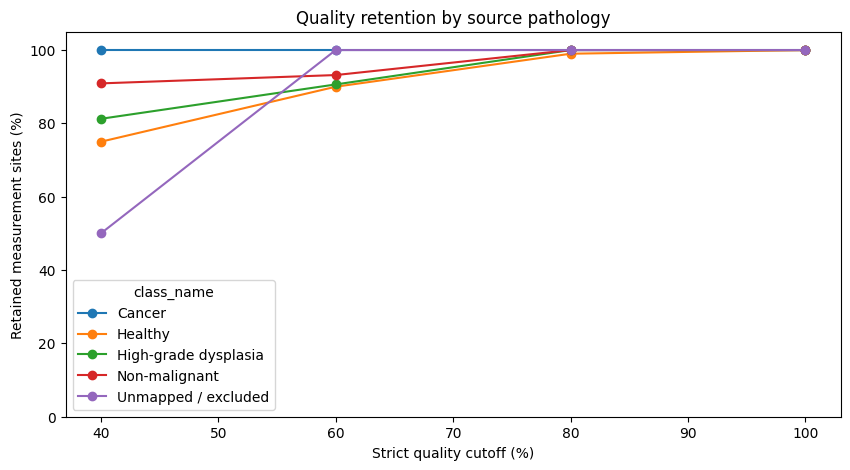

**missing_patterns_by_class** — 5 rows; the CSV contains all rows.

,pathology,count,mean,std,min,median,max
0,Cancer,96,6.095911,6.661122,1.690821,3.040890,31.983264
1,Healthy,100,25.667001,22.377060,2.057453,17.494824,93.672360
2,High-grade dysplasia,32,24.899715,21.077964,2.980504,19.636387,77.329193
3,Non-malignant,44,17.214948,18.136163,2.126467,9.758885,70.445135
4,NaN,4,30.704365,25.075960,2.355072,30.372239,59.717909


**missing_patterns_by_class_location** — 61 rows; the CSV contains all rows.

,pathology,location,count,mean,std
0,Cancer,alveolar ridge,3,2.415459,0.604834
1,Cancer,base tongue,9,5.652366,5.423205
2,Cancer,buccal mucosa,3,2.914366,0.284625
3,Cancer,floor of mouth,1,2.014320,NaN
4,Cancer,floor of the mouth,15,4.520646,3.859887
5,Cancer,gingival mucosa,2,3.506729,1.866586
6,Cancer,hard palate,2,2.680728,0.796044
7,Cancer,lingual aspect of mandible,1,2.251553,NaN
8,Cancer,lingual side (green),1,10.718599,NaN
9,Cancer,oral tongue,31,7.060765,7.265740


**quality_cluster_associations** — 3 rows; the CSV contains all rows.

...

,variable,level,status,wald_chi2,df,p_value,n_patients,method,reason,n_coefficients,covariance_rank,p_holm
0,prior_radiation,No,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
1,prior_radiation,Yes,computed,0.404348,3.0,9.393428e-01,94,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
2,location,oral tongue,computed,15.391316,3.0,1.511015e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.137452e-02
3,location,base tongue,computed,9.982849,3.0,1.871249e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,5.987996e-01
4,location,floor of the mouth,computed,5.576719,3.0,1.341213e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00
5,location,anterior tongue,unavailable,NaN,NaN,NaN,100,NaN,singular or ill-conditioned patient-cluster co...,3.0,1.0,NaN
6,location,tonsil,computed,11.527527,3.0,9.190010e-03,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,3.032703e-01
7,location,buccal mucosa,computed,38.233536,3.0,2.522313e-08,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.828097e-07
8,location,soft palate,computed,9.183887,3.0,2.694333e-02,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,8.352432e-01
9,location,palate,computed,4.859811,3.0,1.823550e-01,100,asymptotic patient-cluster sandwich OLS Wald; ...,NaN,NaN,NaN,1.000000e+00


**missingness_encoding_audit.json**

{'max_reported_vs_observed_difference': 36.15424430641822,
 'n_sites_disagreeing_by_more_than_one_percentage_point': 209,
 'note': 'Observed missing patterns have any non-finite frequency. Avg_Cutpats may be averaged over repeated acquisitions; discrepancies need upstream audit.'}

**source_quality_audit.json**

{'n_sites': 276,
 'all_reported_quality_equals_mean_of_test_quality': True,
 'max_quality_mean_abs_difference': 0.0,
 'n_exported_spectra_equal_nanmean_of_test_means': 276,
 'interpretation': 'Reported Avg_Cutpats is checked against the arithmetic mean of the supplied per-test rejection percentages. Missingness of the final averaged spectrum is a different quantity. This does not reconstruct within-burst filtering or contact controls.',
 'mat_sha256': 'c05c8082b3958df369d2a62abb2b9dfbe6eab8e7a511d339e1f139599c0e832c',
 'script_sha256': 'ce0bac5b3efe55098f2aff2c93fc28b09c70f5341587043d17d9339cbfecb484'}

In [4]:
retention = cread(SNAPSHOT / "quality/retention_by_threshold_class.csv")
retention["class_name"] = retention.class_name.fillna("Unmapped / excluded")
retention["retained_site_percent"] = (
    100 * retention.n_retained_sites / retention.n_total_sites
)
table(retention, "quality-retention-by-class")
curve = retention.pivot(
    index="cutoff", columns="class_name", values="retained_site_percent"
)
ax = curve.plot(
    marker="o",
    figsize=(10, 5),
    ylim=(0, 105),
    ylabel="Retained measurement sites (%)",
    xlabel="Strict quality cutoff (%)",
)
ax.set_title("Quality retention by source pathology")
figure(ax.figure, "quality-retention")
for name in (
    "missing_patterns_by_class",
    "missing_patterns_by_class_location",
    "quality_cluster_associations",
    "covariate_cluster_associations",
):
    path = SNAPSHOT / "quality" / (name + ".csv")
    if path.is_file():
        table(cread(path), name)
for name in ("missingness_encoding_audit.json", "source_quality_audit.json"):
    path = SNAPSHOT / "quality" / name
    if path.is_file():
        display(Markdown("**" + name + "**"))
        display(jread(path))

## 4. Repositioned test-mean repeatability — R1 C24–25

Display the saved coordinate/scalar variability and ICC(2,1) intervals without rerunning bootstrap. Read the stored endpoint and exclusions: the available test means do not recover the nine individual bursts, controlled pressure/angle experiments or pathology registration.


{'status': 'computed',
 'icc_endpoint': 'mean magnitude over available frequencies and patterns per acquisition replicate',
 'icc_model': 'ICC(2,1), absolute agreement; first three available test positions, complete sites; patient-cluster intervals',
 'n_replicates': 4,
 'caveat': 'Only supplied replicate units are analyzed. The two to four MATLAB Full_data spectra are test means, not nine bursts; within-burst repeatability is unavailable. Multiple sites within patients are clustered for intervals.'}

**saved-icc-and-patient-bootstrap-intervals** — 5 rows; the CSV contains all rows.

,class_name,n_sites,icc_2_1_absolute,balanced_icc_sites,balanced_icc_replicates,icc_ci_low,icc_ci_high,valid_cluster_bootstraps,between_site_sd
0,All,276,0.915723,274,3,0.886939,0.939942,1000,252.803002
1,Healthy,100,0.851177,100,3,0.774169,0.908951,1000,201.405185
2,Cancer,96,0.931818,95,3,0.890645,0.956170,1000,170.761702
3,Non-malignant,44,0.802229,44,3,0.577712,0.926342,1000,213.357189
4,High-grade dysplasia,32,0.877517,31,3,0.709385,0.954505,1000,233.354006


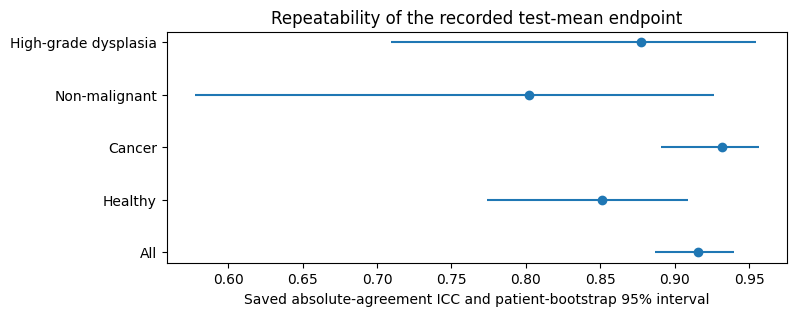

**saved-site-repeatability-by-pathology** — 5 rows; the CSV contains all rows.

,pathology,n_samples,n_patients,mean_coordinate_cv,mean_scalar_repeat_cv,mean_repositioning_sd
0,Cancer,96,70,0.267598,0.103617,29.952888
1,Healthy,100,95,0.279574,0.106500,62.716906
2,High-grade dysplasia,32,21,0.309234,0.113051,61.131842
3,Non-malignant,44,28,0.308480,0.139748,71.675798
4,NaN,4,4,0.312125,0.098415,54.436626


In [5]:
repeat_status = jread(SNAPSHOT / "repeatability/status.json")
display(repeat_status)
icc_path = SNAPSHOT / "repeatability/icc_and_inter_site_variability.csv"
if icc_path.is_file():
    icc = cread(icc_path)
    table(icc, "saved-icc-and-patient-bootstrap-intervals")
    finite = icc[["icc_2_1_absolute", "icc_ci_low", "icc_ci_high"]].notna().all(axis=1)
    shown = icc.loc[finite].reset_index(drop=True)
    if len(shown):
        fig, ax = plt.subplots(figsize=(8, max(3, 0.5 * len(shown))))
        for i, row in shown.iterrows():
            ax.plot(row.icc_2_1_absolute, i, "o", color="tab:blue")
            ax.hlines(i, row.icc_ci_low, row.icc_ci_high, color="tab:blue")
        ax.set_yticks(range(len(shown)), shown.class_name)
        ax.set(
            xlabel="Saved absolute-agreement ICC and patient-bootstrap 95% interval",
            title="Repeatability of the recorded test-mean endpoint",
        )
        figure(fig, "saved-test-mean-icc")
site_repeat_path = SNAPSHOT / "repeatability/site_repeatability.csv"
if site_repeat_path.is_file():
    repeat = cread(site_repeat_path, dtype={"patient_id": str, "sample_id": str})
    table(
        repeat.groupby("pathology", dropna=False)
        .agg(
            n_samples=("sample_id", "size"),
            n_patients=("patient_id", "nunique"),
            mean_coordinate_cv=("mean_coordinate_cv", "mean"),
            mean_scalar_repeat_cv=("scalar_repeat_cv", "mean"),
            mean_repositioning_sd=("repositioning_sd", "mean"),
        )
        .reset_index(),
        "saved-site-repeatability-by-pathology",
    )

## 5. Completed-fold partitions, pathology and coverage — R1 C1–3, C7–8, C10, M6; R3 C1

These tables cover only copied completed folds. They verify patient separation, inner-fit provenance and training-only postprocessing, and describe inclusion/quality coverage. Section 6 separately displays descriptive classification previews, explicitly recording their incomplete population. Neither section selects a winner using outer-test scores or extrapolates missing folds.


In [6]:
population_rows, pathology_rows, coverage_rows, failure_rows = [], [], [], []
for folder, marker in FOLDS:
    inclusion = cread(
        folder / "task_inclusion.csv", dtype={"patient_id": str, "sample_id": str}
    )
    classes = jread(folder / "classes.json")["classes"]
    inclusion["task_class"] = inclusion.class_index.map(dict(enumerate(classes)))
    if not inclusion.sample_id.is_unique:
        raise ValueError(f"Duplicate task inclusion IDs: {folder}")
    splits = jread(folder / "splits.json")
    if len(splits) != 1:
        raise ValueError(f"Expected exactly one split in {folder}")
    split = splits[0]
    actual_key = (split["repeat"], split["outer_fold"], split["evaluation"])
    if actual_key != tuple(marker["fold_key"]):
        raise ValueError("Split and completion marker identities disagree.")
    train, test = set(split["train_patients"]), set(split["test_patients"])
    if train & test or len(split["inner"]) != cfg["inner_folds"]:
        raise ValueError("Invalid outer partition or inner-fold count.")
    roles = [
        (-1, "outer_train", split["train_sample_ids"]),
        (-1, "outer_test", split["test_sample_ids"]),
    ]
    for inner_fold, inner in enumerate(split["inner"]):
        a, b = set(inner["train_patients"]), set(inner["validation_patients"])
        if a & b or a | b != train:
            raise ValueError("Invalid inner patient partition.")
        roles.extend(
            [
                (inner_fold, "inner_train", inner["train_sample_ids"]),
                (inner_fold, "inner_validation", inner["validation_sample_ids"]),
            ]
        )
    base = {
        "task": marker["task"],
        "repeat": split["repeat"],
        "outer_fold": split["outer_fold"],
        "evaluation": split["evaluation"],
    }
    for inner_fold, role, sample_ids in roles:
        members = inclusion.set_index("sample_id").loc[sample_ids].reset_index()
        for cutoff in [None, *sorted(set(cfg["cutoffs"] + [cfg["default_cutoff"]]))]:
            retained = (
                members if cutoff is None else members[members.missing_percent < cutoff]
            )
            identity = {
                **base,
                "inner_fold": inner_fold,
                "partition": role,
                "population": "unfiltered" if cutoff is None else "quality_retained",
                "cutoff": cutoff,
            }
            population_rows.append(
                {
                    **identity,
                    "n_samples": len(retained),
                    "n_patients": retained.patient_id.nunique(),
                    "n_quality_excluded_sites": len(members) - len(retained),
                }
            )
            for (label, raw), group in retained.groupby(
                ["task_class", "raw_pathology"], dropna=False
            ):
                pathology_rows.append(
                    {
                        **identity,
                        "task_class": label,
                        "raw_pathology": raw,
                        "n_samples": len(group),
                        "n_patients": group.patient_id.nunique(),
                    }
                )
    for selection in jread(folder / "selections.json"):
        fit_ids = set(selection["postprocessing_fit_sample_ids"])
        if (
            not fit_ids <= set(split["train_sample_ids"])
            or set(selection["postprocessing_fit_patient_ids"]) - train
        ):
            raise ValueError(
                "Postprocessing provenance crosses the outer training boundary."
            )
        fits = selection["inner_fit_provenance"]
        if len(fits) != len(split["inner"]):
            raise ValueError("Missing inner-fit provenance.")
        for fit, inner in zip(fits, split["inner"]):
            if not set(fit["train_patients"]) <= set(inner["train_patients"]) or set(
                fit["test_patients"]
            ) != set(inner["validation_patients"]):
                raise ValueError("Inner fit crosses its recorded training boundary.")
    predictions = cread(
        folder / "outer_predictions.csv", dtype={"patient_id": str, "sample_id": str}
    )
    for stream, group in predictions.groupby("stream"):
        if (
            set(group.sample_id) != set(split["test_sample_ids"])
            or group.sample_id.duplicated().any()
        ):
            raise ValueError("Incomplete or duplicate test coverage.")
        if not group.covered.isin([True, False]).all():
            raise ValueError("Invalid covered flags.")
        coverage_rows.append(
            {
                **base,
                "stream": stream,
                "n_samples": len(group),
                "n_patients": group.patient_id.nunique(),
                "n_covered": int(group.covered.sum()),
                "site_coverage": float(group.covered.mean()),
            }
        )
    for failure in jread(folder / "candidate_failures.json"):
        failure_rows.append(
            {
                **base,
                "reason": failure["reason"],
                "candidate": json.dumps(failure["candidate"], sort_keys=True),
            }
        )
table(population_rows, "completed-fold-populations")
table(pathology_rows, "completed-fold-raw-pathology")
table(coverage_rows, "completed-fold-quality-coverage")
table(failure_rows, "completed-fold-candidate-failures")

**completed-fold-populations** — 900 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,inner_fold,partition,population,cutoff,n_samples,n_patients,n_quality_excluded_sites
0,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,231,81,0
1,MC,0,0,nested_cv,-1,outer_train,quality_retained,40.000000,198,77,33
2,MC,0,0,nested_cv,-1,outer_train,quality_retained,60.000000,216,80,15
3,MC,0,0,nested_cv,-1,outer_train,quality_retained,80.000000,230,80,1
4,MC,0,0,nested_cv,-1,outer_train,quality_retained,100.000001,231,81,0
5,MC,0,0,nested_cv,-1,outer_test,unfiltered,NaN,41,19,0
6,MC,0,0,nested_cv,-1,outer_test,quality_retained,40.000000,39,19,2
7,MC,0,0,nested_cv,-1,outer_test,quality_retained,60.000000,40,19,1
8,MC,0,0,nested_cv,-1,outer_test,quality_retained,80.000000,41,19,0
9,MC,0,0,nested_cv,-1,outer_test,quality_retained,100.000001,41,19,0


**completed-fold-raw-pathology** — 5967 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,inner_fold,partition,population,cutoff,task_class,raw_pathology,n_samples,n_patients
0,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Cancer,invasive carcinoma,80,54
1,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Healthy,healthy,83,78
2,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,cis,5,4
3,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high grade dysplasia,2,2
4,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high-grade dysplasia,6,6
5,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high-grade dysplasia /cis,1,1
6,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,high-grade dysplasia/ cis,7,3
7,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,High-grade dysplasia,moderate dysplasia,8,7
8,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Non-malignant,benign,30,18
9,MC,0,0,nested_cv,-1,outer_train,unfiltered,NaN,Non-malignant,mild dysplasia,9,6


**completed-fold-quality-coverage** — 792 rows; the CSV contains all rows.

,task,repeat,outer_fold,evaluation,stream,n_samples,n_patients,n_covered,site_coverage
0,MC,0,0,nested_cv,ablation_imputation_mean,41,19,40,0.97561
1,MC,0,0,nested_cv,ablation_imputation_median,41,19,40,0.97561
2,MC,0,0,nested_cv,ablation_imputation_zero,41,19,40,0.97561
3,MC,0,0,nested_cv,ablation_missingness,41,19,40,0.97561
4,MC,0,0,nested_cv,ablation_normalization_freq,41,19,40,0.97561
5,MC,0,0,nested_cv,ablation_normalization_global,41,19,40,0.97561
6,MC,0,0,nested_cv,ablation_normalization_none,41,19,40,0.97561
7,MC,0,0,nested_cv,ablation_quality_100.000001,41,19,41,1.00000
8,MC,0,0,nested_cv,ablation_quality_40,41,19,39,0.95122
9,MC,0,0,nested_cv,ablation_quality_60,41,19,40,0.97561


**completed-fold-candidate-failures** — 0 rows; the CSV contains all rows.

""


""


## 6. Descriptive classifier preview — ROC/AUC, confusion matrices and four tuning objectives

Only hash-verified completed checkpoints are read. For each task, the table prints `auc`, `acc`, `f1` and `sensitivity` for pipelines tuned toward **auc, acc, f1 and sensitivity**, for SVM, RF, LR and the training-selected model (`*_selected`). A tuning objective is distinct from the reported metric. The selected model may differ between outer folds; no winner is chosen using these preview scores.

Metrics pool **covered measurement sites in copied outer-test folds**, with equal site weight. Binary AUC/F1/sensitivity refer to the recorded positive class (Cancer or High risk); multiclass AUC is macro one-versus-rest, F1 is macro and sensitivity is macro recall. `dysplasia_sensitivity` separately shows high-grade dysplasia recall, the multiclass sensitivity-tuning target. Saved `y_pred` decisions are used unchanged, including training-selected thresholds in sensitivity streams.

Coverage, copied/expected folds and the fraction of the task population represented are printed with every row. Abstentions are excluded from diagnostic metrics but counted in coverage; absent classes produce undefined AUCs. Each patient/site occurs only once per stream. This preview supports the configured **single outer partition**; repeated partitions must use the final reporting workflow. No confidence intervals or significance tests are calculated. Partial-fold previews must not be used for final reviewer claims or manuscript results.


In [7]:
import sys
import numpy as np

if cfg["outer_repeats"] != 1:
    raise ValueError("Snapshot classifier previews require one outer partition; use final reporting for repeats.")

# Reuse the server metric definitions only when the local source matches every checkpoint.
CLASSIFIER_CODE_HASHES = {
    name: sha(ROOT / name) for name in ("revision/metrics.py", "revision/features.py")
}
for folder, marker in FOLDS:
    recorded = marker["source_version"]["hashes"]
    if any(recorded.get(name) != digest for name, digest in CLASSIFIER_CODE_HASHES.items()):
        raise ValueError(f"Metric source differs from {folder}; use its matching source version.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from revision.metrics import scores

OBJECTIVES = ("auc", "acc", "f1", "sensitivity")
PREVIEW = {}
metric_rows, class_rows = [], []
for task in cfg["tasks"]:
    folds = [(folder, marker) for folder, marker in FOLDS if marker["task"] == task]
    if not folds:
        display(Markdown(f"**{task}:** no copied completed folds; no classifier preview."))
        continue
    classes_info = jread(folds[0][0] / "classes.json")
    classes = classes_info["classes"]
    pcols = [f"p_{k}" for k in range(len(classes))]
    mapping = dict(zip(pcols, classes))
    if classes_info["probability_columns"] != mapping or (
        len(classes) == 2 and classes_info.get("positive_class") != classes[1]
    ):
        raise ValueError(f"Ambiguous probability/positive-class mapping: {task}")
    inclusion = cread(folds[0][0] / "task_inclusion.csv", dtype={"patient_id": str, "sample_id": str})
    reference = inclusion.set_index("sample_id")
    if not reference.index.is_unique:
        raise ValueError(f"Duplicate task inclusion IDs: {task}")
    wanted = {f"{goal}_{model}" for goal in OBJECTIVES for model in [*cfg["models"], "selected"]}
    frames = []
    for folder, marker in folds:
        if jread(folder / "classes.json") != classes_info:
            raise ValueError(f"Class/probability metadata differs across folds: {task}")
        split = jread(folder / "splits.json")[0]
        frame = cread(folder / "outer_predictions.csv", dtype={"patient_id": str, "sample_id": str})
        repeat, fold, evaluation = marker["fold_key"]
        if not (frame.task.eq(task) & frame["repeat"].eq(repeat)
                & frame.outer_fold.eq(fold) & frame.evaluation.eq(evaluation)).all():
            raise ValueError(f"Prediction identities disagree with checkpoint: {folder}")
        frame = frame.loc[frame.stream.isin(wanted)].copy()
        if set(frame.stream) != wanted or not frame.covered.isin([True, False]).all():
            raise ValueError(f"Missing requested streams or invalid coverage flags: {folder}")
        for stream, group in frame.groupby("stream"):
            if group.sample_id.duplicated().any() or set(group.sample_id) != set(split["test_sample_ids"]):
                raise ValueError(f"Incomplete or duplicate outer-test records: {folder}/{stream}")
            if not set(group.patient_id) <= set(split["test_patients"]):
                raise ValueError(f"Prediction patients disagree with outer split: {folder}/{stream}")
            if not group.objective.eq(stream.rsplit("_", 1)[0]).all():
                raise ValueError(f"Unexpected tuning objective: {folder}/{stream}")
        ref = reference.loc[frame.sample_id]
        if not (np.array_equal(ref.patient_id.to_numpy(), frame.patient_id.to_numpy())
                and np.array_equal(ref.class_index.to_numpy(), frame.y_true.to_numpy())):
            raise ValueError(f"Prediction labels/patients disagree with task inclusion: {folder}")
        frames.append(frame)
    predictions = pd.concat(frames, ignore_index=True)
    if predictions.duplicated(["stream", "sample_id"]).any() or (
        predictions.groupby(["stream", "patient_id"]).outer_fold.nunique() > 1
    ).any():
        raise ValueError(f"Repeated test patients/sites in the single-partition preview: {task}")
    scheduled = sum(t == task for t, key in expected)
    status = "ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED" if len(folds) == scheduled else "PARTIAL FOLDS; PRELIMINARY"
    for stream, group in predictions.groupby("stream", sort=True):
        covered = group.loc[group.covered].copy()
        summary = dict.fromkeys(("auc", "accuracy", "f1", "sensitivity"), np.nan)
        dysplasia_sensitivity = np.nan
        if not covered.empty:
            probabilities = covered[pcols].to_numpy(float)
            y = covered.y_true.to_numpy(int)
            if not covered.y_pred.isin(range(len(classes))).all():
                raise ValueError(f"Invalid saved class decisions: {task}/{stream}")
            decisions = covered.y_pred.to_numpy(int)
            if (not np.isfinite(probabilities).all()
                    or ((probabilities < 0) | (probabilities > 1)).any()
                    or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
                    or not np.isin(y, range(len(classes))).all()
                    or not np.isin(decisions, range(len(classes))).all()):
                raise ValueError(f"Invalid covered labels/decisions/probabilities: {task}/{stream}")
            summary, perclass, cm = scores(y, probabilities, decisions)
            # Catch axis/order or dropped-record mistakes before exporting results.
            assert cm.shape == (len(classes), len(classes)) and cm.sum() == len(covered)
            assert np.array_equal(cm.sum(axis=1), np.bincount(y, minlength=len(classes)))
            class_frame = perclass.assign(class_name=classes, task=task, stream=stream, status=status)
            class_rows.append(class_frame)
            if "High-grade dysplasia" in classes:
                dysplasia_sensitivity = perclass.iloc[classes.index("High-grade dysplasia")].sensitivity
            PREVIEW[(task, stream)] = (covered, classes, cm, summary, len(folds), scheduled, len(group), status)
        metric_rows.append({
            "task": task, "stream": stream, "objective": group.objective.iloc[0],
            "models_used": ",".join(sorted(group.model.unique())),
            "folds_copied": len(folds), "folds_expected": scheduled,
            "task_sites_total": len(inclusion), "sites_in_copied_folds": len(group),
            "patients_in_copied_folds": group.patient_id.nunique(), "sites_covered": len(covered),
            "site_coverage": len(covered) / len(group), "task_site_fraction": len(group) / len(inclusion),
            "auc": summary["auc"], "acc": summary["accuracy"], "f1": summary["f1"],
            "sensitivity": summary["sensitivity"], "dysplasia_sensitivity": dysplasia_sensitivity,
            "status": status,
        })
CLASSIFICATION_SUMMARY = pd.DataFrame(metric_rows)
if not CLASSIFICATION_SUMMARY.empty:
    CLASSIFICATION_SUMMARY.to_csv(OUT / "classification-metrics-all-streams.csv", index=False)
    with pd.option_context("display.max_columns", None, "display.precision", 3):
        for task, group in CLASSIFICATION_SUMMARY.groupby("task", sort=False):
            table(group, f"classification-metrics-{task}")
if class_rows:
    pd.concat(class_rows, ignore_index=True).to_csv(OUT / "classification-per-class-metrics.csv", index=False)


**classification-metrics-healthy_vs_cancer** — 16 rows; the CSV contains all rows.

,task,stream,objective,models_used,folds_copied,folds_expected,task_sites_total,sites_in_copied_folds,patients_in_copied_folds,sites_covered,site_coverage,task_site_fraction,auc,acc,f1,sensitivity,dysplasia_sensitivity,status
0,healthy_vs_cancer,acc_lr,acc,lr,4,5,196,151,78,150,0.993,0.77,0.874,0.820,0.811,0.773,NaN,PARTIAL FOLDS; PRELIMINARY
1,healthy_vs_cancer,acc_rf,acc,rf,4,5,196,151,78,150,0.993,0.77,0.859,0.793,0.783,0.747,NaN,PARTIAL FOLDS; PRELIMINARY
2,healthy_vs_cancer,acc_selected,acc,"rf,svm",4,5,196,151,78,150,0.993,0.77,0.846,0.800,0.789,0.747,NaN,PARTIAL FOLDS; PRELIMINARY
3,healthy_vs_cancer,acc_svm,acc,svm,4,5,196,151,78,150,0.993,0.77,0.857,0.827,0.819,0.787,NaN,PARTIAL FOLDS; PRELIMINARY
4,healthy_vs_cancer,auc_lr,auc,lr,4,5,196,151,78,150,0.993,0.77,0.867,0.813,0.803,0.760,NaN,PARTIAL FOLDS; PRELIMINARY
5,healthy_vs_cancer,auc_rf,auc,rf,4,5,196,151,78,150,0.993,0.77,0.859,0.787,0.784,0.773,NaN,PARTIAL FOLDS; PRELIMINARY
6,healthy_vs_cancer,auc_selected,auc,"rf,svm",4,5,196,151,78,150,0.993,0.77,0.867,0.793,0.797,0.813,NaN,PARTIAL FOLDS; PRELIMINARY
7,healthy_vs_cancer,auc_svm,auc,svm,4,5,196,151,78,150,0.993,0.77,0.891,0.813,0.818,0.840,NaN,PARTIAL FOLDS; PRELIMINARY
8,healthy_vs_cancer,f1_lr,f1,lr,4,5,196,151,78,150,0.993,0.77,0.868,0.827,0.817,0.773,NaN,PARTIAL FOLDS; PRELIMINARY
9,healthy_vs_cancer,f1_rf,f1,rf,4,5,196,151,78,150,0.993,0.77,0.857,0.793,0.786,0.760,NaN,PARTIAL FOLDS; PRELIMINARY


**classification-metrics-cancer_vs_lr_hr** — 16 rows; the CSV contains all rows.

,task,stream,objective,models_used,folds_copied,folds_expected,task_sites_total,sites_in_copied_folds,patients_in_copied_folds,sites_covered,site_coverage,task_site_fraction,auc,acc,f1,sensitivity,dysplasia_sensitivity,status
16,cancer_vs_lr_hr,acc_lr,acc,lr,5,5,172,172,97,172,1.0,1.0,0.771,0.622,0.490,0.486,0.219,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
17,cancer_vs_lr_hr,acc_rf,acc,rf,5,5,172,172,97,172,1.0,1.0,0.723,0.576,0.423,0.426,0.188,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
18,cancer_vs_lr_hr,acc_selected,acc,"lr,svm",5,5,172,172,97,172,1.0,1.0,0.744,0.610,0.483,0.480,0.281,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
19,cancer_vs_lr_hr,acc_svm,acc,svm,5,5,172,172,97,172,1.0,1.0,0.730,0.610,0.475,0.475,0.219,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
20,cancer_vs_lr_hr,auc_lr,auc,lr,5,5,172,172,97,172,1.0,1.0,0.754,0.610,0.452,0.466,0.344,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
21,cancer_vs_lr_hr,auc_rf,auc,rf,5,5,172,172,97,172,1.0,1.0,0.745,0.570,0.415,0.427,0.281,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
22,cancer_vs_lr_hr,auc_selected,auc,"lr,rf,svm",5,5,172,172,97,172,1.0,1.0,0.751,0.605,0.479,0.478,0.250,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
23,cancer_vs_lr_hr,auc_svm,auc,svm,5,5,172,172,97,172,1.0,1.0,0.731,0.581,0.468,0.467,0.281,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
24,cancer_vs_lr_hr,f1_lr,f1,lr,5,5,172,172,97,172,1.0,1.0,0.751,0.640,0.499,0.496,0.219,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
25,cancer_vs_lr_hr,f1_rf,f1,rf,5,5,172,172,97,172,1.0,1.0,0.743,0.616,0.484,0.481,0.250,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED


**classification-metrics-MC** — 16 rows; the CSV contains all rows.

,task,stream,objective,models_used,folds_copied,folds_expected,task_sites_total,sites_in_copied_folds,patients_in_copied_folds,sites_covered,site_coverage,task_site_fraction,auc,acc,f1,sensitivity,dysplasia_sensitivity,status
32,MC,acc_lr,acc,lr,4,5,272,209,79,208,0.995,0.768,0.686,0.567,0.333,0.396,0.0,PARTIAL FOLDS; PRELIMINARY
33,MC,acc_rf,acc,rf,4,5,272,209,79,208,0.995,0.768,0.700,0.572,0.338,0.400,0.0,PARTIAL FOLDS; PRELIMINARY
34,MC,acc_selected,acc,"rf,svm",4,5,272,209,79,208,0.995,0.768,0.701,0.591,0.381,0.426,0.0,PARTIAL FOLDS; PRELIMINARY
35,MC,acc_svm,acc,svm,4,5,272,209,79,208,0.995,0.768,0.692,0.596,0.385,0.429,0.0,PARTIAL FOLDS; PRELIMINARY
36,MC,auc_lr,auc,lr,4,5,272,209,79,208,0.995,0.768,0.678,0.553,0.327,0.388,0.0,PARTIAL FOLDS; PRELIMINARY
37,MC,auc_rf,auc,rf,4,5,272,209,79,208,0.995,0.768,0.739,0.596,0.353,0.418,0.0,PARTIAL FOLDS; PRELIMINARY
38,MC,auc_selected,auc,rf,4,5,272,209,79,208,0.995,0.768,0.739,0.596,0.353,0.418,0.0,PARTIAL FOLDS; PRELIMINARY
39,MC,auc_svm,auc,svm,4,5,272,209,79,208,0.995,0.768,0.685,0.587,0.346,0.412,0.0,PARTIAL FOLDS; PRELIMINARY
40,MC,f1_lr,f1,lr,4,5,272,209,79,208,0.995,0.768,0.685,0.572,0.340,0.402,0.0,PARTIAL FOLDS; PRELIMINARY
41,MC,f1_rf,f1,rf,4,5,272,209,79,208,0.995,0.768,0.699,0.553,0.333,0.387,0.0,PARTIAL FOLDS; PRELIMINARY


**classification-metrics-highrisk_vs_lowrisk** — 16 rows; the CSV contains all rows.

,task,stream,objective,models_used,folds_copied,folds_expected,task_sites_total,sites_in_copied_folds,patients_in_copied_folds,sites_covered,site_coverage,task_site_fraction,auc,acc,f1,sensitivity,dysplasia_sensitivity,status
48,highrisk_vs_lowrisk,acc_lr,acc,lr,5,5,272,272,100,271,0.996,1.0,0.752,0.731,0.692,0.641,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
49,highrisk_vs_lowrisk,acc_rf,acc,rf,5,5,272,272,100,271,0.996,1.0,0.778,0.756,0.708,0.625,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
50,highrisk_vs_lowrisk,acc_selected,acc,"rf,svm",5,5,272,272,100,271,0.996,1.0,0.792,0.756,0.711,0.633,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
51,highrisk_vs_lowrisk,acc_svm,acc,svm,5,5,272,272,100,271,0.996,1.0,0.772,0.764,0.722,0.648,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
52,highrisk_vs_lowrisk,auc_lr,auc,lr,5,5,272,272,100,271,0.996,1.0,0.717,0.694,0.647,0.594,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
53,highrisk_vs_lowrisk,auc_rf,auc,rf,5,5,272,272,100,271,0.996,1.0,0.793,0.727,0.681,0.617,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
54,highrisk_vs_lowrisk,auc_selected,auc,"rf,svm",5,5,272,272,100,271,0.996,1.0,0.786,0.731,0.689,0.633,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
55,highrisk_vs_lowrisk,auc_svm,auc,svm,5,5,272,272,100,271,0.996,1.0,0.780,0.738,0.705,0.664,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
56,highrisk_vs_lowrisk,f1_lr,f1,lr,5,5,272,272,100,271,0.996,1.0,0.752,0.731,0.692,0.641,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED
57,highrisk_vs_lowrisk,f1_rf,f1,rf,5,5,272,272,100,271,0.996,1.0,0.775,0.749,0.696,0.609,NaN,ALL TASK FOLDS COPIED; FINAL RUN UNVERIFIED


### ROC curves and confusion matrices

By default, plot the four **training-selected** pipelines per task. To inspect fixed model families, replace `_selected` in `PLOT_STREAMS` with `_svm`, `_rf` or `_lr`; metric tables above already contain all of them. Each figure includes ROC/AUC, confusion counts and row-normalized confusion proportions, using the saved class order and saved decisions. Binary ROC shows the positive class; multiclass ROC is one-versus-rest. A missing reference class has no ROC and its normalized confusion row is undefined (`nan`). Every title states the copied-fold and covered-site counts and the preliminary status. Files are exported as CSV, PNG and PDF; no paper files are modified.


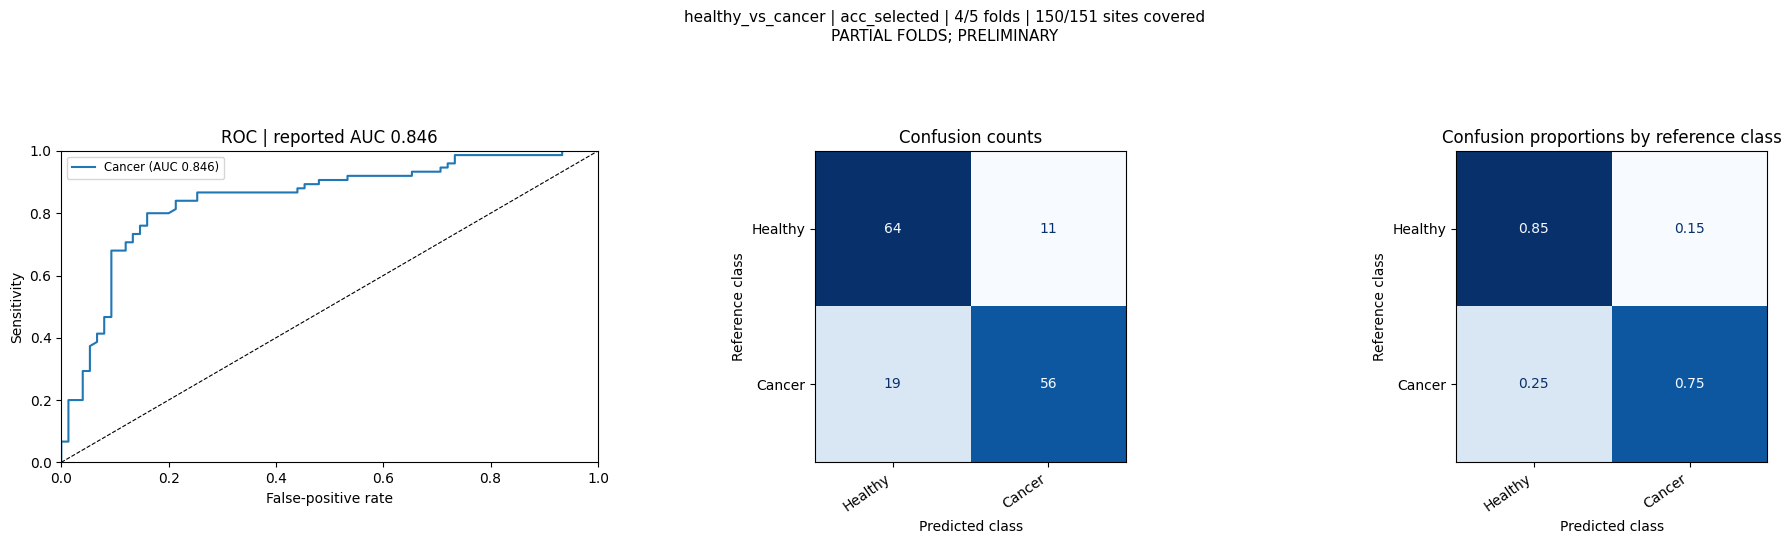

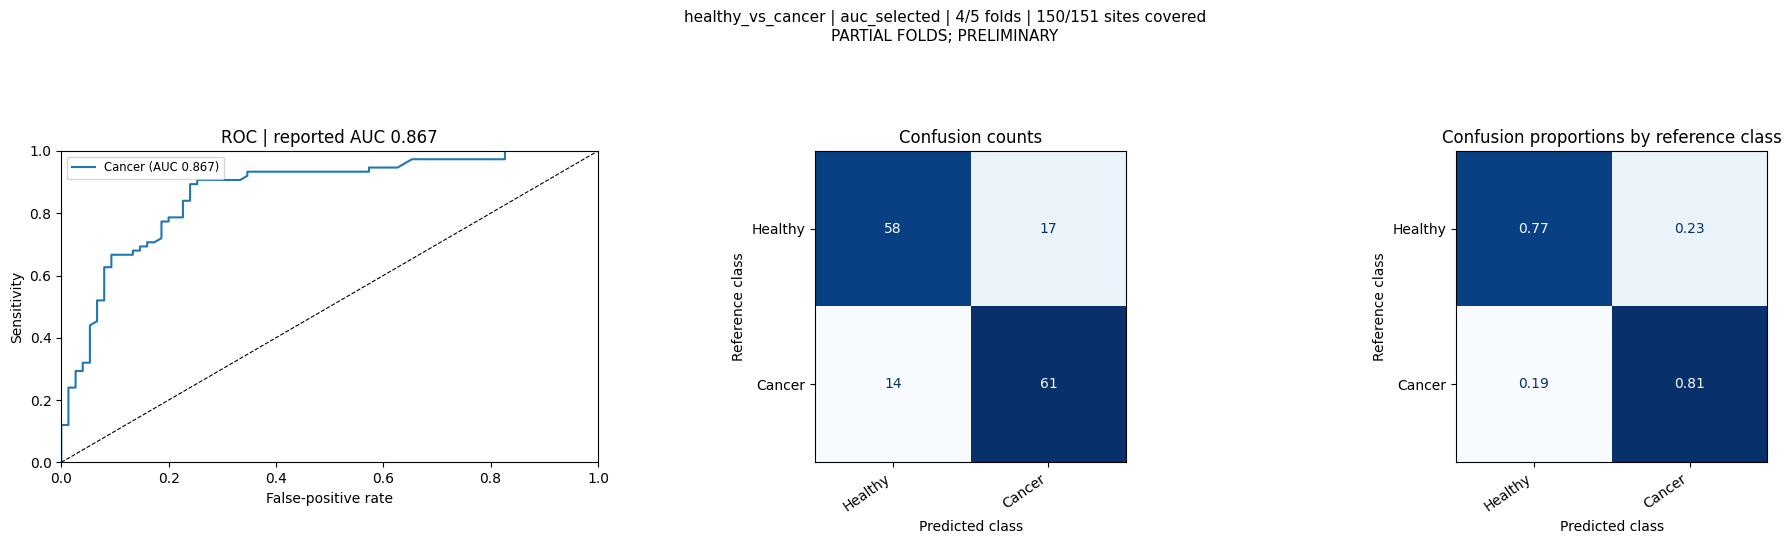

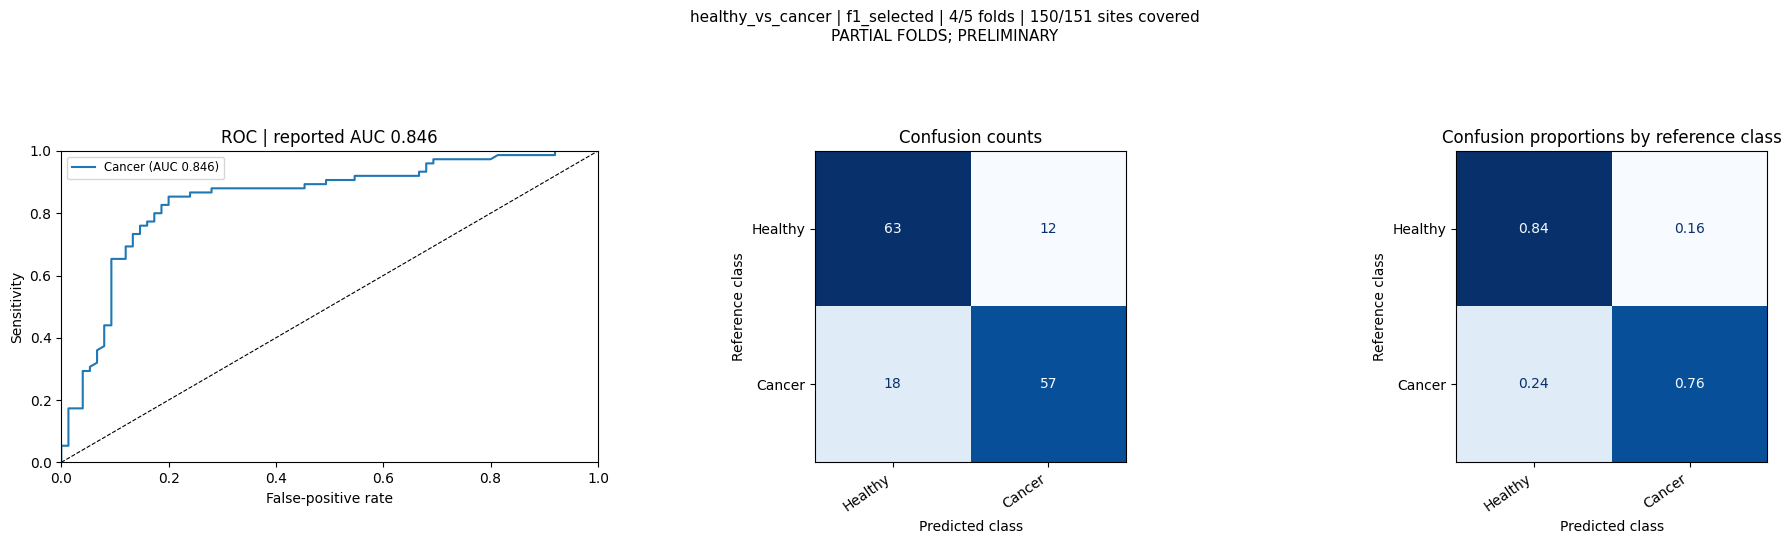

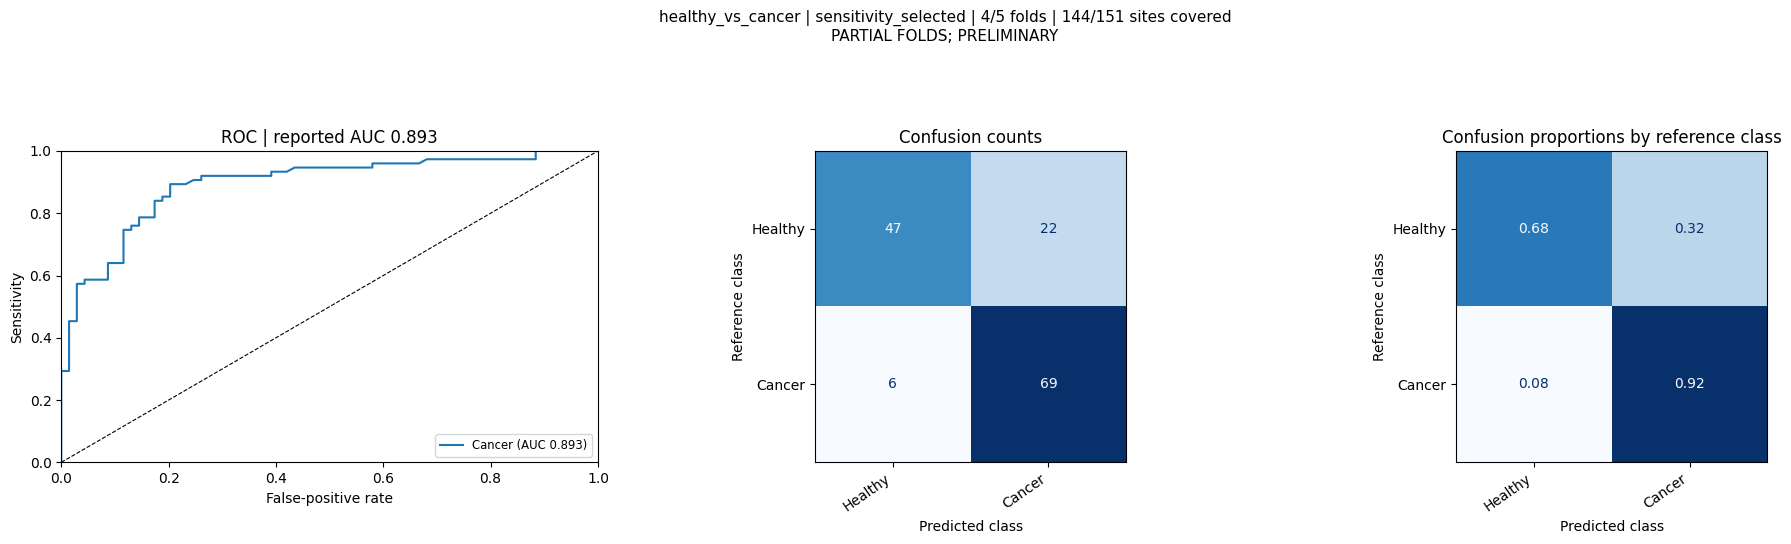

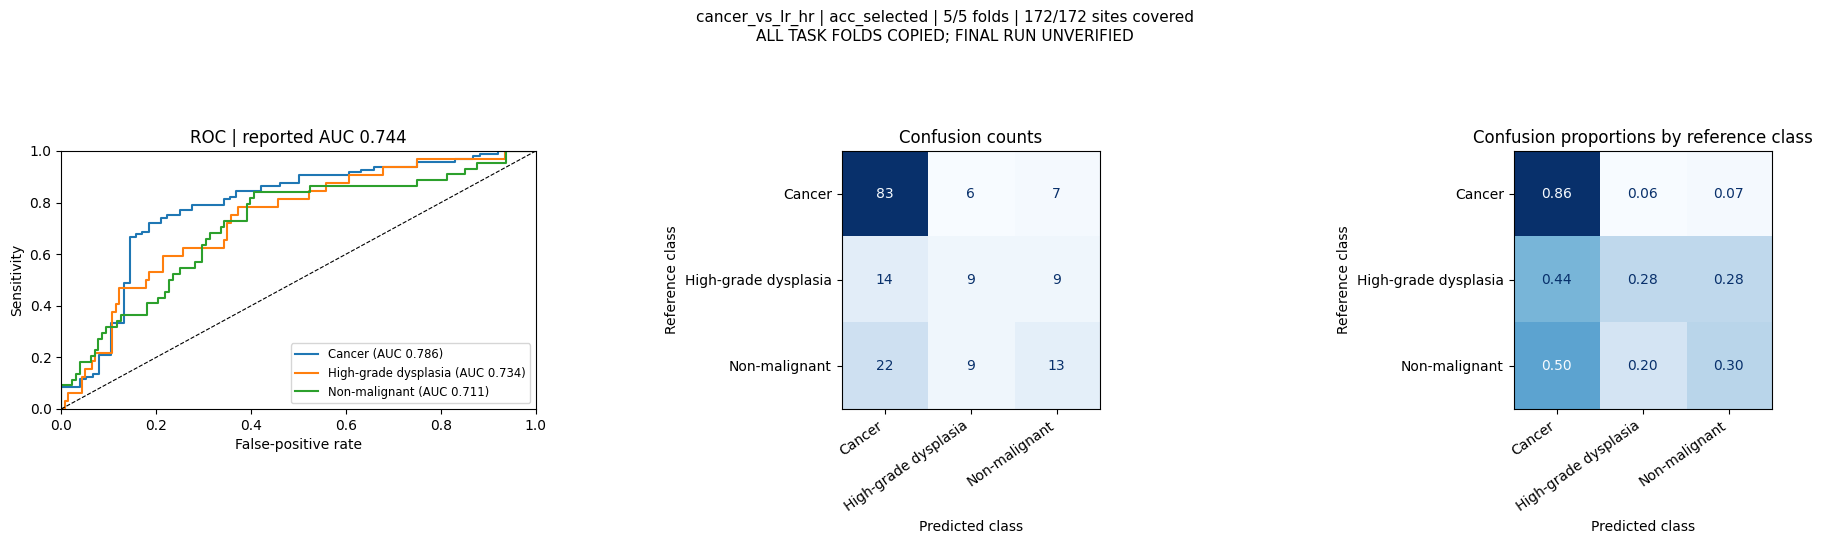

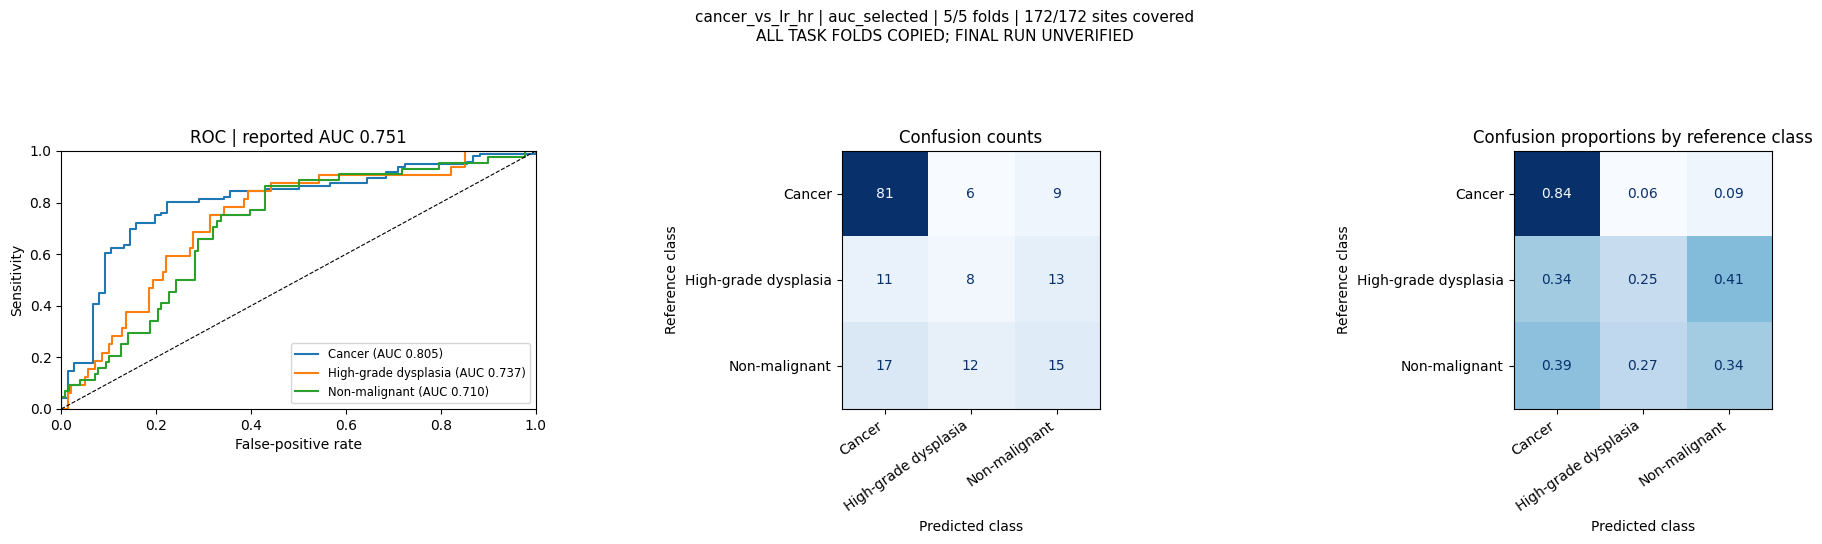

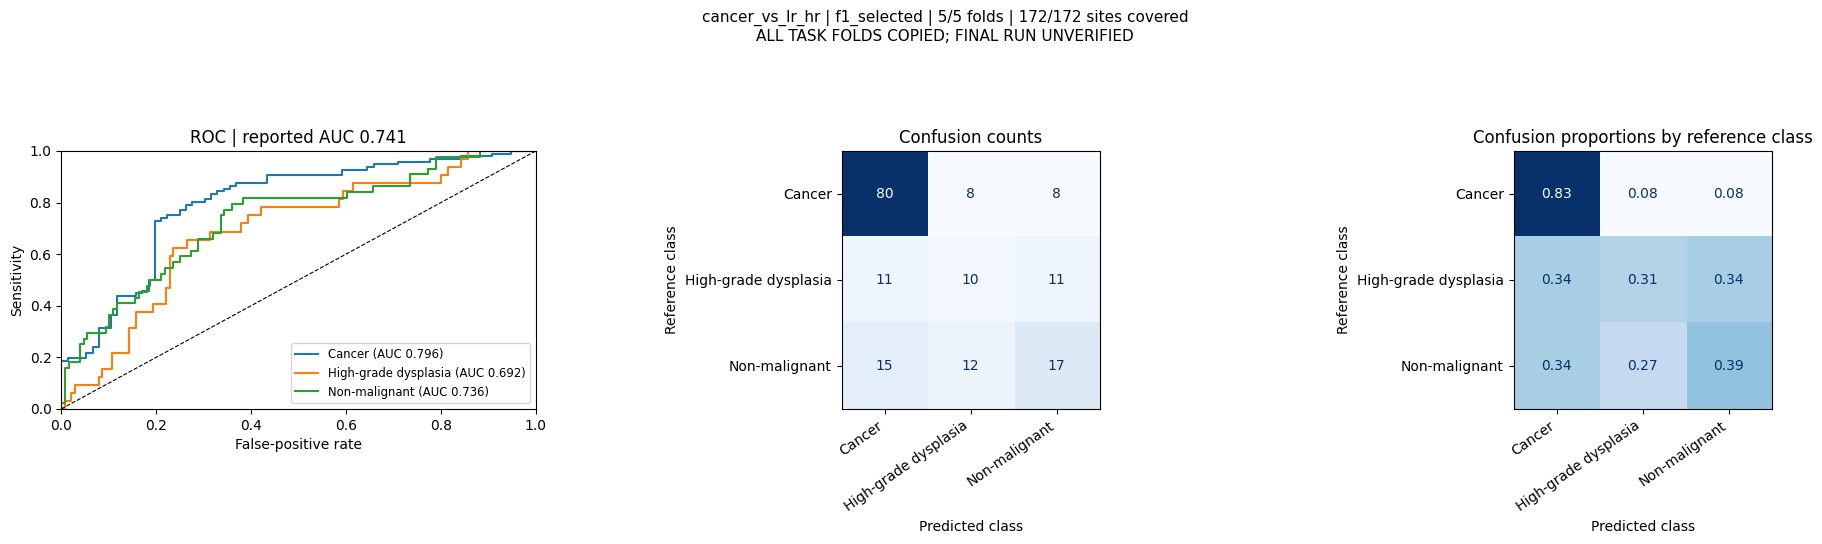

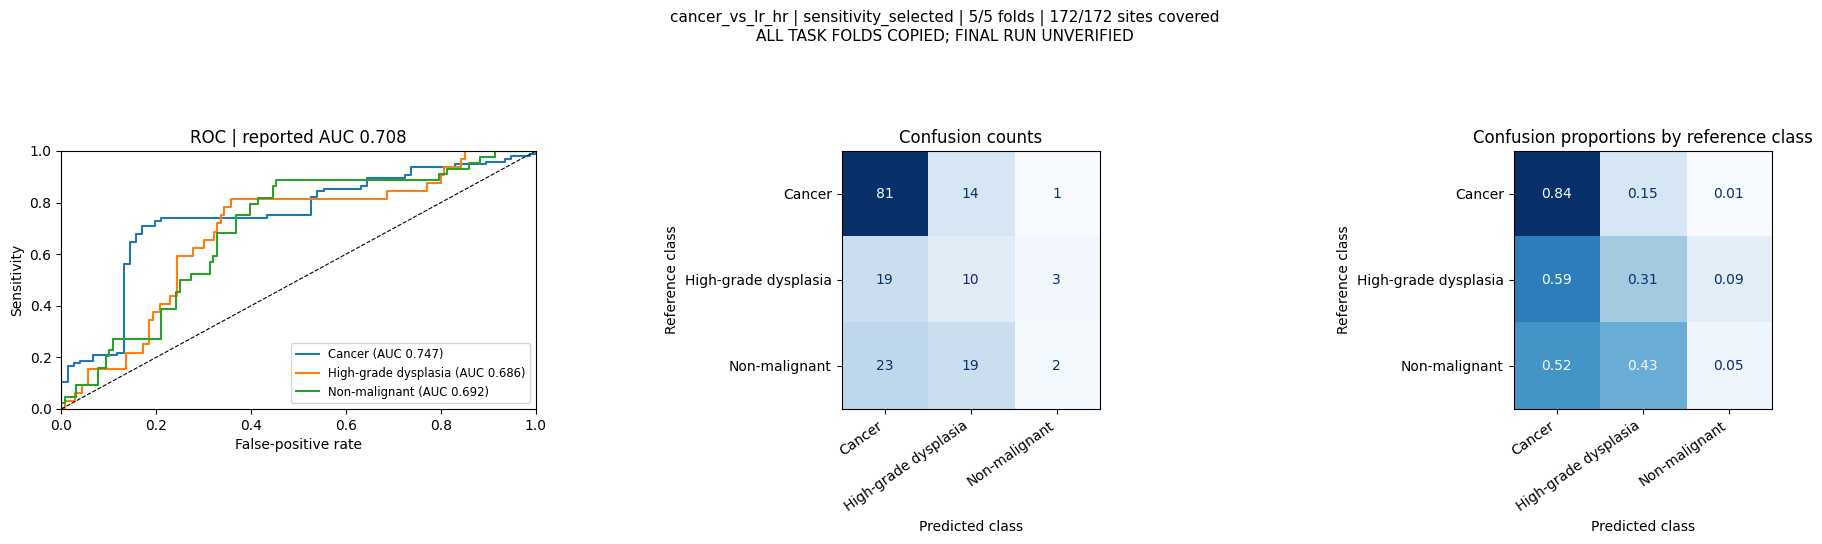

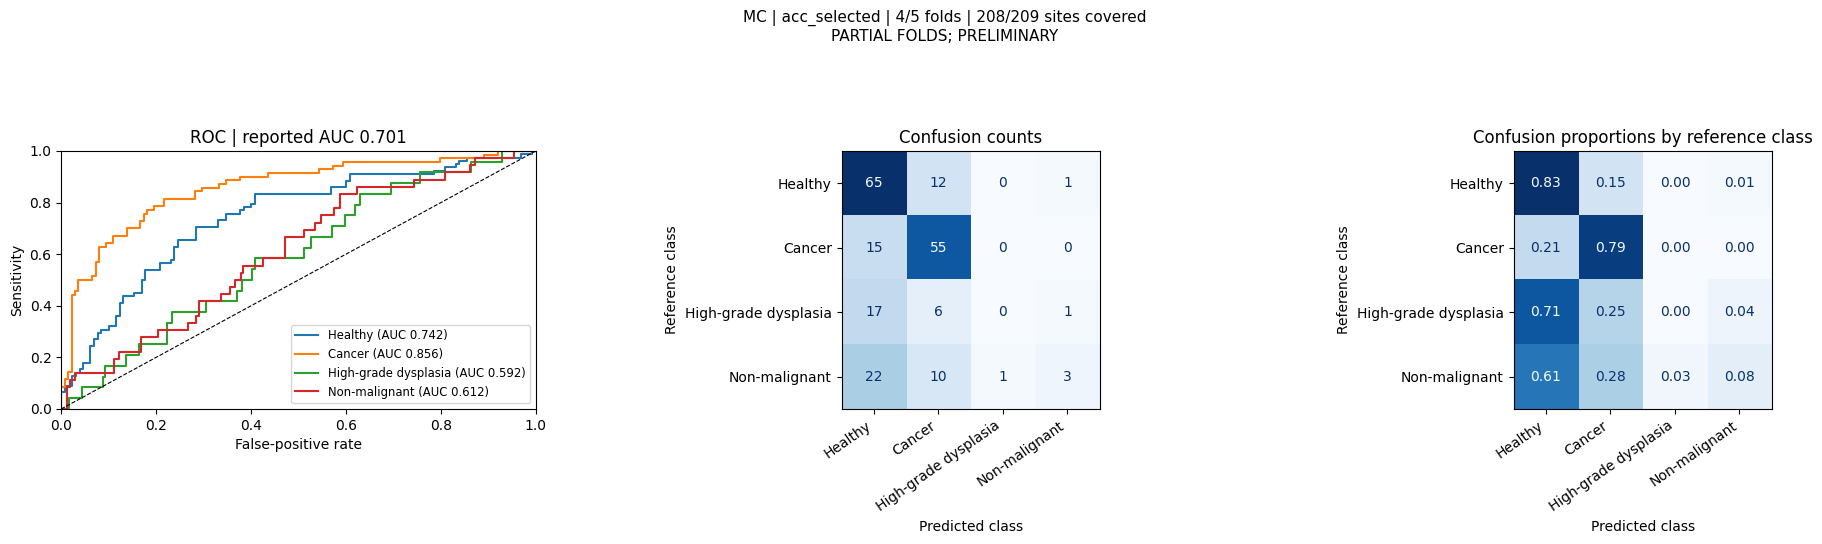

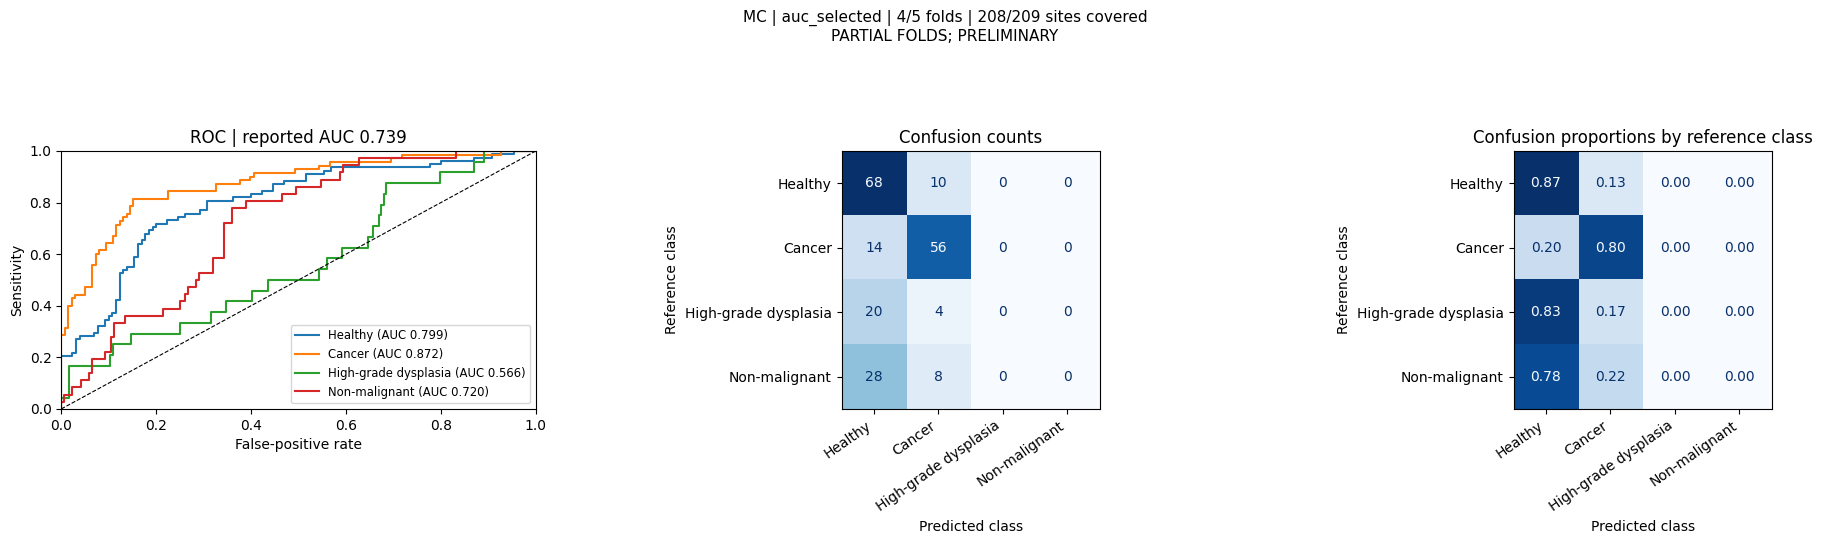

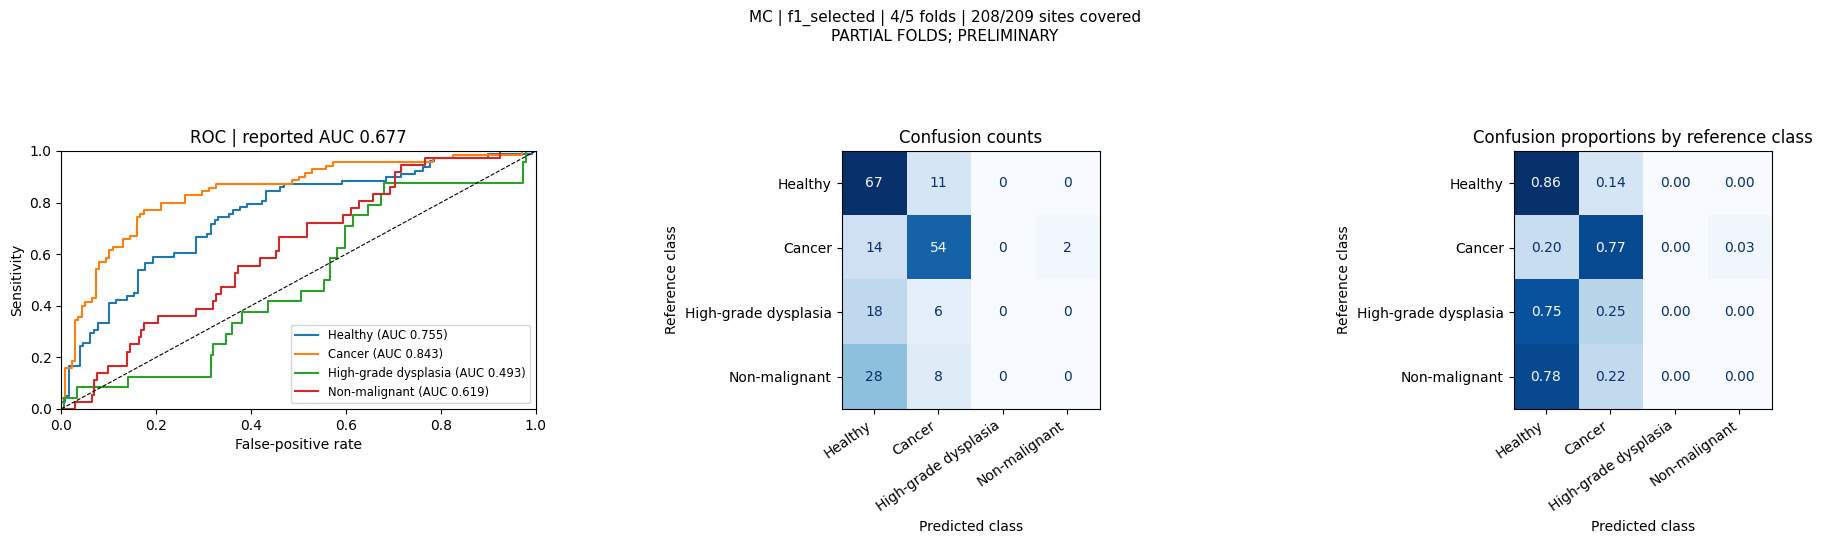

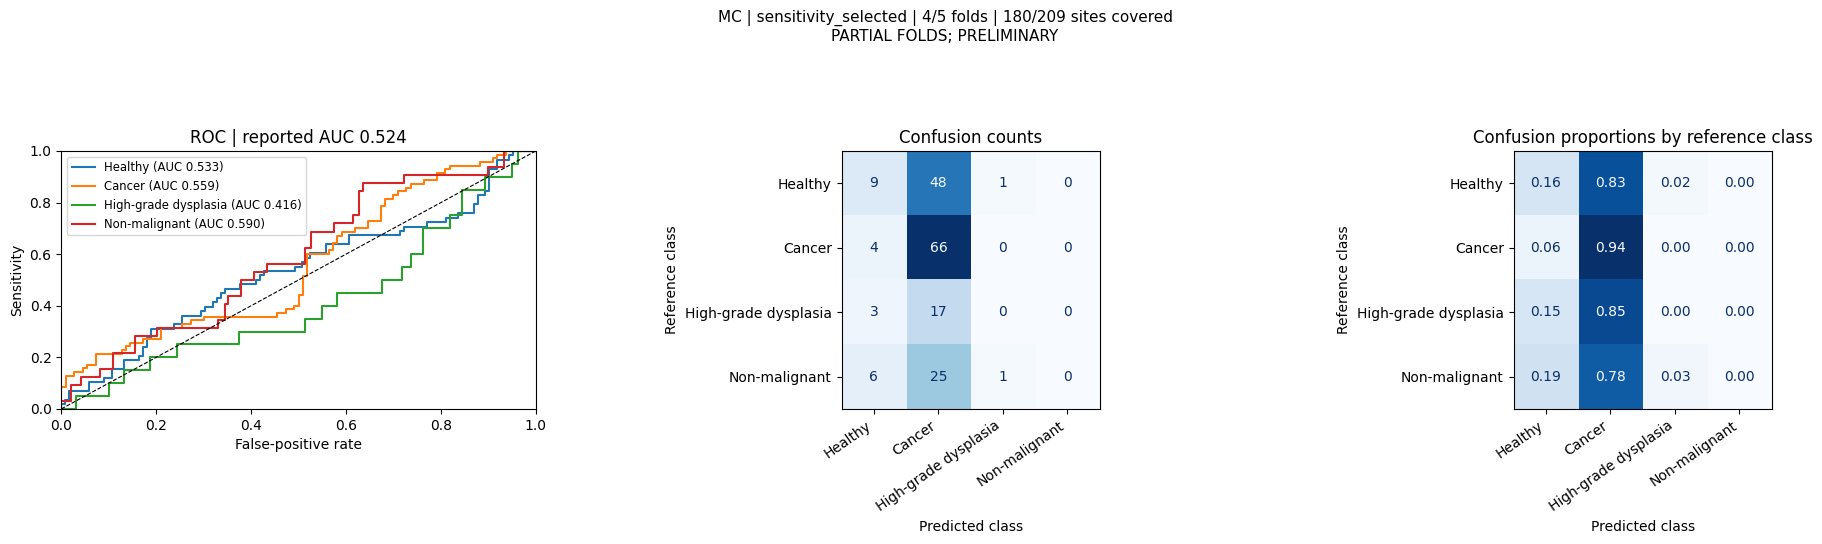

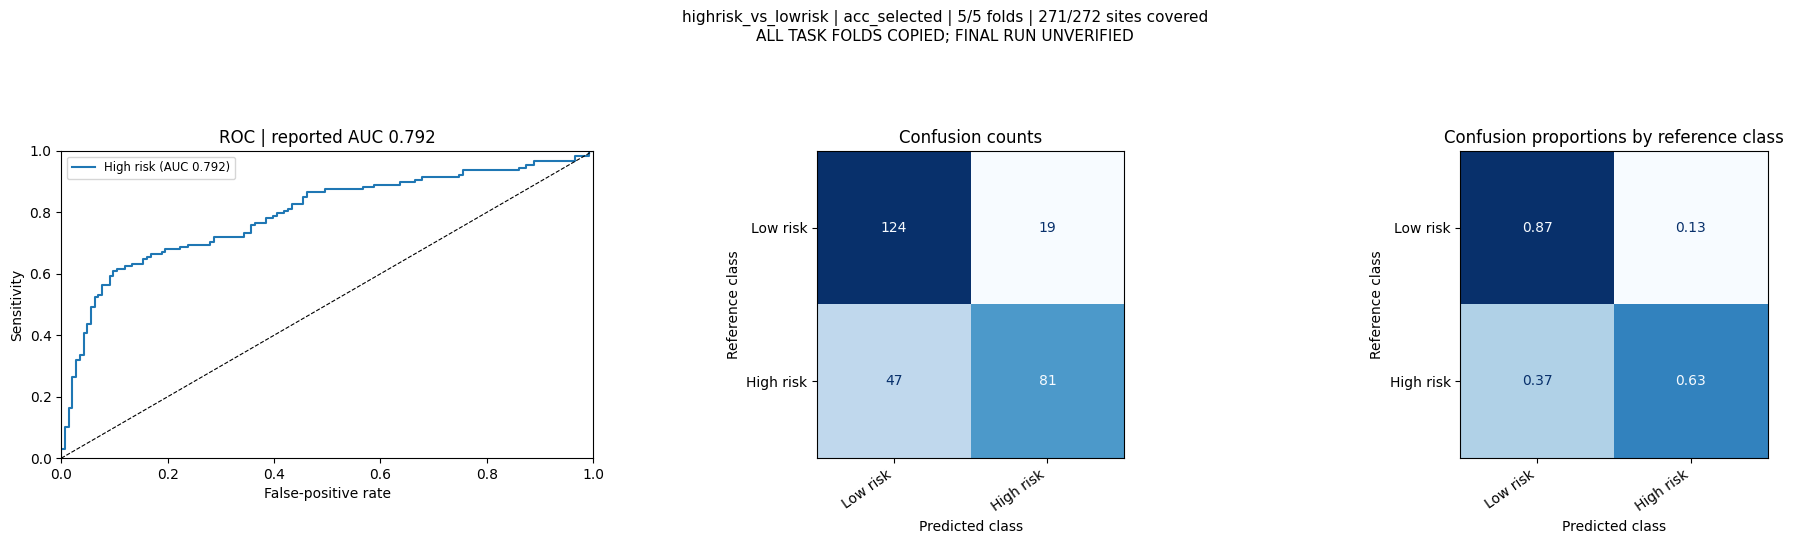

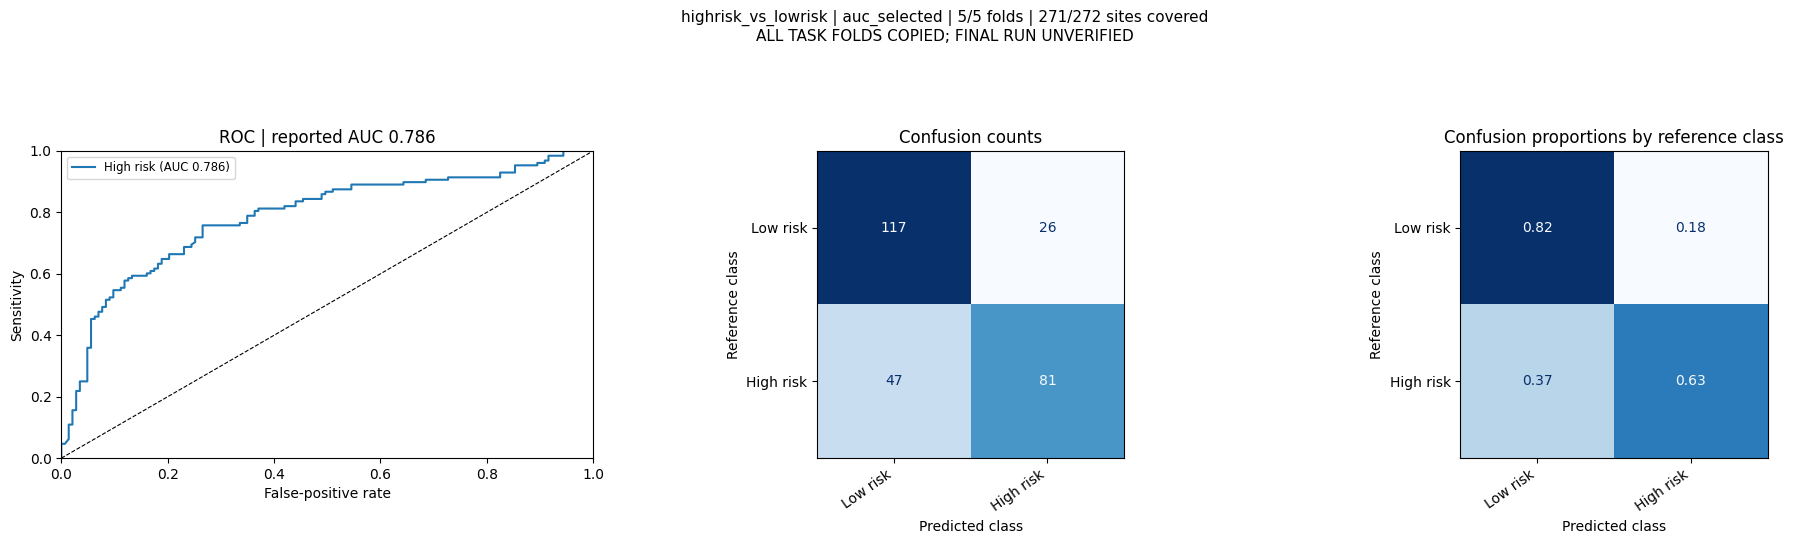

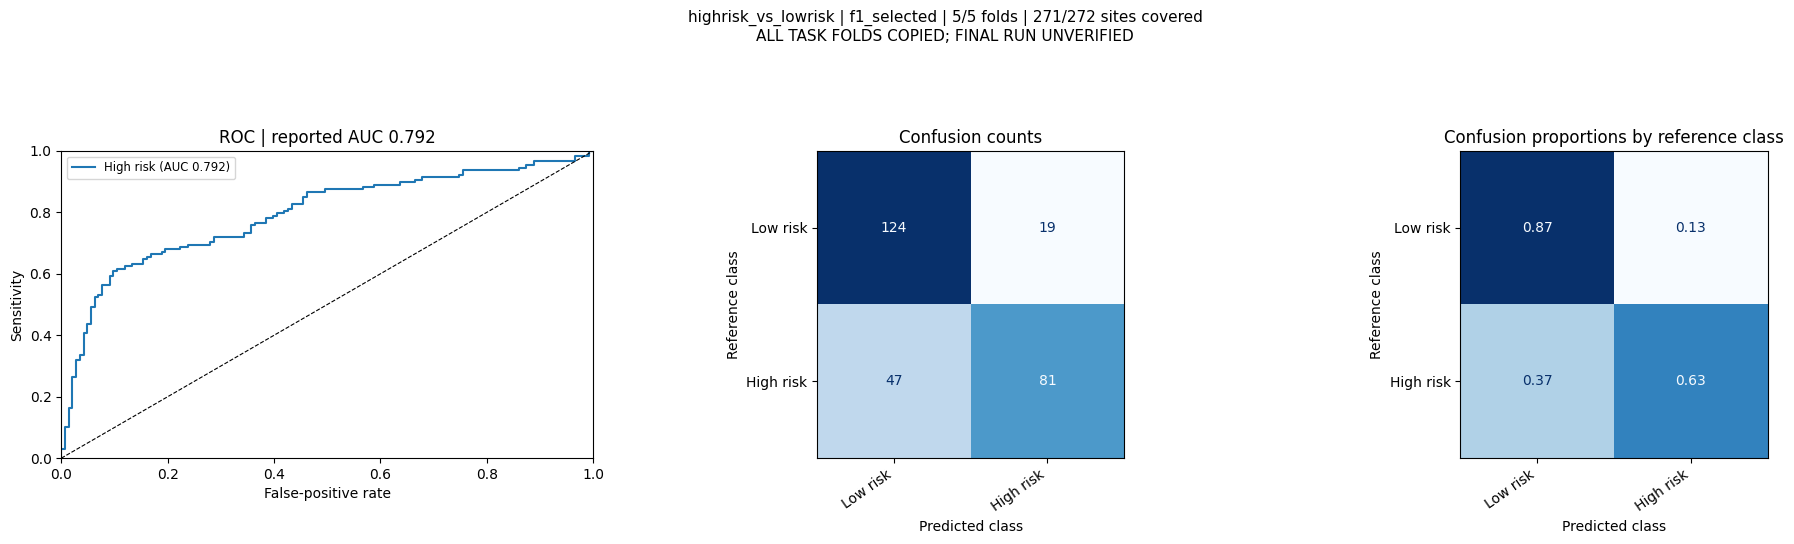

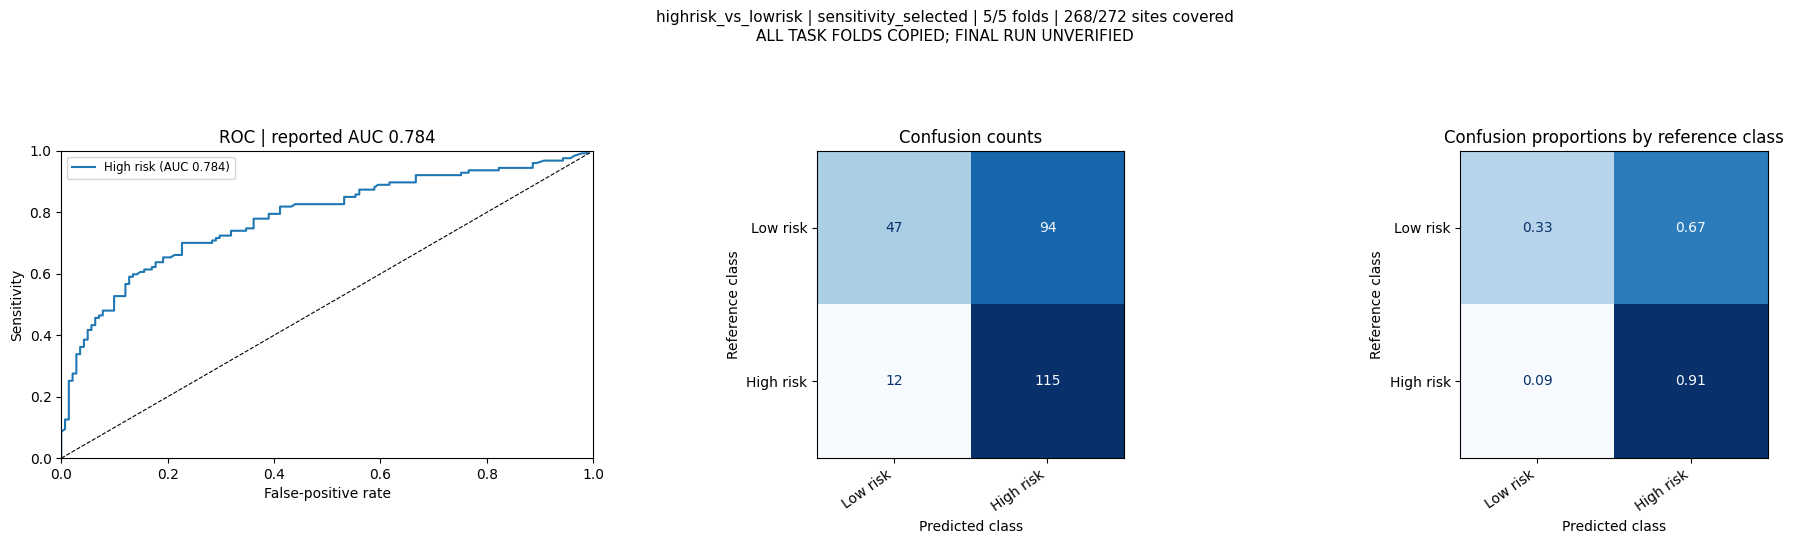

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, auc, roc_curve

PLOT_STREAMS = [f"{goal}_selected" for goal in OBJECTIVES]
for (task, stream), (covered, classes, cm, summary, nfolds, scheduled, nsites, status) in PREVIEW.items():
    if stream not in PLOT_STREAMS:
        continue
    prefix = f"classification-{task}-{stream}"
    title = f"{task} | {stream} | {nfolds}/{scheduled} folds | {len(covered)}/{nsites} sites covered\n{status}"
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
    curve_rows = []
    for k in ([1] if len(classes) == 2 else range(len(classes))):
        truth = covered.y_true.to_numpy(int) == k
        if np.unique(truth).size < 2:
            continue
        fpr, tpr, thresholds = roc_curve(truth, covered[f"p_{k}"].to_numpy(float))
        class_auc = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, label=f"{classes[k]} (AUC {class_auc:.3f})")
        curve_rows.extend({"class_name": classes[k], "class_index": k, "fpr": x, "tpr": y, "threshold": threshold}
                          for x, y, threshold in zip(fpr, tpr, thresholds))
    axes[0].plot([0, 1], [0, 1], "k--", linewidth=0.8)
    axes[0].set(xlabel="False-positive rate", ylabel="Sensitivity", title=f"ROC | reported AUC {summary['auc']:.3f}", xlim=(0, 1), ylim=(0, 1))
    if curve_rows:
        axes[0].legend(fontsize="small")
        pd.DataFrame(curve_rows).to_csv(OUT / (prefix + "-roc.csv"), index=False)
    else:
        axes[0].text(0.5, 0.5, "ROC undefined: insufficient classes", ha="center")
    normalized = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.full_like(cm, np.nan), where=cm.sum(axis=1, keepdims=True) > 0)
    for ax, values, label, fmt in [(axes[1], cm.astype(int), "Confusion counts", "d"),
                                  (axes[2], normalized, "Confusion proportions by reference class", ".2f")]:
        ConfusionMatrixDisplay(values, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=fmt, colorbar=False)
        ax.set(title=label, xlabel="Predicted class", ylabel="Reference class")
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
    for suffix, values in [("counts", cm.astype(int)), ("row-normalized", normalized)]:
        pd.DataFrame(values, index=classes, columns=classes).rename_axis("reference_class").to_csv(OUT / (prefix + "-confusion-" + suffix + ".csv"))
    fig.suptitle(title, fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    figure(fig, prefix + "-roc-confusion")


### Training-selected parameter combinations in copied completed folds

This section reads only the hash-verified `FOLDS` inventory. It works while the run is ongoing and also after all fold folders have been copied. Missing folds remain absent; the recorded run status is never changed. Default streams show the four overall training-selected winners; set `SELECTION_STREAMS` to model-specific streams if needed. Each task's parameter table is exported under `OUT` as `selected-parameter-combinations-<task>.csv` and included in the final provenance inventory.

Until final reporting, selections are available at `fold-checkpoints/<task>/nested_cv_repeat<r>_fold<f>/selections.json`; the associated `inner_search.csv` contains the candidate search. The summary shown separately below pools saved predictions from copied folds and is **not a fold-specific score for each displayed parameter row**. Snapshot partial-task metrics remain preliminary; this section does not recompute metrics, fit models, tune thresholds, or perform resampling.

After the full run completes, use `Figures-and-Tables.ipynb` for the verified final results and saved uncertainty reports.

| Saved file under the run directory | Contents |
|---|---|
| `<task>/selections.json` | Training-selected model, full hyperparameters, preprocessing, thresholds and actual selected coordinates for each outer fold and stream |
| `<task>/inner_search.csv` | All evaluated inner-search candidates, coverage and `objective_auc`, `objective_acc`, `objective_f1`, `objective_sensitivity` scores |
| `<task>/frequency_and_pattern_identities.json` | Physical frequency identities and selected IIVV coordinate indices for each outer-training refit |
| `<task>/outer_fold_metrics.csv` | Held-out results separately by outer fold and evaluation unit |
| `<task>/metrics_summary.csv` / `all_metrics.csv` | Pooled outer predictions summarized by task, stream and evaluation unit |
| `<task>/classification_outputs.csv` / `classification_outputs.csv` | Diagnostic estimates with saved confidence intervals and reporting metadata |
| `BaselineResults.csv` / `FinalResults.csv` | Baseline and non-baseline metric summaries; `FinalResults.csv` also includes controls/ablations, not one global winner |

`auc_selected`, `acc_selected`, `f1_selected` and `sensitivity_selected` identify the model family and settings selected **inside each outer-training population**. For a model-specific winner use, for example, `auc_rf`, `auc_svm` or `auc_lr`. A different model or parameter combination can win in every fold. Do not select a new winner by sorting held-out AUC: pooled results describe the selection procedure, not the performance of one frozen configuration. The displayed inner score is the stored coverage-adjusted selection objective, not held-out performance.

No single deployment model is automatically refitted on all patients after CV. With `save_models: false`, parameter records and predictions are saved, but fitted model objects are not. Circuit descriptors may require all acquired frequencies even when their scalar feature count is small.


In [ ]:
def selected_parameter_table(records):
    chosen = [r for r in records if r["stream"] in SELECTION_STREAMS and r["evaluation"] == "nested_cv"]
    if not chosen:
        return pd.DataFrame()
    frame = pd.json_normalize(chosen)
    frame["specificity_thresholds"] = [r["specificity_thresholds"] for r in chosen]
    keys = ["task", "stream", "evaluation", "repeat", "outer_fold"]
    if frame.duplicated(keys).any():
        raise ValueError("Duplicate outer-fold selection identities.")
    if not frame.model.eq(frame["candidate.model"]).all():
        raise ValueError("Selected model disagrees with candidate metadata.")
    # Check physical frequency identities against their independently saved indices.
    assert all(len(r["frequencies_hz"]) == len(r["frequency_indices_0based"]) for r in chosen), "Frequency identities and indices disagree."
    params = frame["candidate.params_json"].map(json.loads)
    if not params.map(lambda value: isinstance(value, dict)).all():
        raise ValueError("Model parameters must be JSON objects.")
    frame["model_parameters"] = params.map(lambda value: json.dumps(value, sort_keys=True))
    frame["n_frequencies"] = frame.frequencies_hz.map(len)
    frame["n_patterns"] = frame.pattern_indices_0based.map(len)
    columns = {
        "task":"task", "repeat":"repeat", "outer_fold":"outer_fold", "evaluation":"evaluation",
        "stream":"stream", "objective":"objective", "model":"model",
        "inner_selection_objective":"inner_selection_score", "model_parameters":"model_parameters",
        "candidate.cutoff":"quality_cutoff", "candidate.normalization":"normalization",
        "candidate.imputation":"imputation", "candidate.class_weight":"class_weight",
        "candidate.patient_weighted":"patient_weighted_training", "candidate.selector":"selector",
        "candidate.representation":"representation", "candidate.mask":"mask",
        "z_threshold_ohm":"z_threshold_ohm", "n_frequencies":"n_frequencies", "frequencies_hz":"frequencies_hz",
        "n_patterns":"n_patterns", "input_features":"input_features", "calibration":"calibration",
        "sensitivity_threshold":"training_sensitivity_threshold", "specificity_thresholds":"training_specificity_thresholds",
    }
    missing = set(columns) - set(frame.columns)
    if missing:
        raise ValueError(f"Selection schema is missing columns: {sorted(missing)}")
    return frame[list(columns)].rename(columns=columns).sort_values(keys).reset_index(drop=True)

SELECTION_STREAMS = [f"{goal}_selected" for goal in cfg["objectives"]]

display(Markdown(f"**Copied run directory:** `{SNAPSHOT}`"))
for task in cfg["tasks"]:
    completed = [(folder, marker) for folder, marker in FOLDS if marker["task"] == task]
    if not completed:
        display(Markdown(f"**{task}:** no copied completed-fold selections."))
        continue
    records = []
    for folder, marker in completed:
        values = jread(folder / "selections.json")
        for value in values:
            identity = (value["repeat"], value["outer_fold"], value["evaluation"])
            if value["task"] != task or identity != tuple(marker["fold_key"]):
                raise ValueError(f"Selection identity disagrees with its checkpoint: {folder}")
        records.extend(values)
    selected = selected_parameter_table(records)
    wanted = {tuple(marker["fold_key"]) for folder, marker in completed if marker["fold_key"][2] == "nested_cv"}
    for stream in SELECTION_STREAMS:
        group = selected[selected.stream == stream] if not selected.empty else pd.DataFrame()
        observed = set(zip(group["repeat"], group.outer_fold, group.evaluation)) if not group.empty else set()
        if observed != wanted:
            raise ValueError(f"Missing selected settings in copied folds: {task}/{stream}")
    if selected.empty:
        continue
    scheduled = sum(t == task for t, key in expected)
    selected["folds_copied"] = len(completed)
    selected["folds_expected"] = scheduled
    selected["scope"] = "copied completed folds; final run not certified by this notebook"
    display(Markdown(f"### {task}: {len(completed)}/{scheduled} copied folds"))
    with pd.option_context("display.max_rows", None, "display.max_columns", None, "display.max_colwidth", None):
        table(selected, f"selected-parameter-combinations-{task}")
        if not CLASSIFICATION_SUMMARY.empty:
            summary = CLASSIFICATION_SUMMARY[(CLASSIFICATION_SUMMARY.task == task) & CLASSIFICATION_SUMMARY.stream.isin(SELECTION_STREAMS)]
            display(Markdown("**Separate pooled snapshot results; not per-fold parameter scores**"))
            display(summary)


## 7. Evidence provenance and next steps

The exports support cohort/quality/repeatability and implementation evidence. Classifier previews are descriptive, conditional on the copied folds and covered sites, and are explicitly marked when incomplete. Final corrected CV tests, comparisons and manuscript numerical imports wait for all scheduled folds and the completed-run check. Recopy new completed folds and restart/run this notebook to obtain a new snapshot directory. If the manifest records a resumed run, also transfer its resume-parent manifests.

Do not change the original manifest status or disable the completion guards in the final-result notebooks.


In [9]:
provenance = {
    "kind": "server snapshot analysis; descriptive classifier preview; no final classification inference",
    "snapshot": str(SNAPSHOT),
    "snapshot_hash": SNAPSHOT_HASH,
    "recorded_run_status": manifest["status"],
    "scheduled_folds": len(expected),
    "copied_completed_folds": len(FOLDS),
    "classification_metrics_aggregated": not CLASSIFICATION_SUMMARY.empty,
    "classification_scope": "descriptive covered-site metrics from copied completed folds; no final inference",
    "classification_code_sha256": CLASSIFIER_CODE_HASHES,
    "fitting_or_resampling_performed": False,
    "input_artifact_sha256": INPUTS,
    "output_artifact_sha256": {
        p.name: sha(p)
        for p in sorted(OUT.iterdir())
        if p.is_file() and p.name != "snapshot-provenance.json"
    },
}
(OUT / "snapshot-provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
display(Markdown(f"Tables and PDF/PNG figures saved to **{OUT.relative_to(ROOT)}**."))
display(pd.DataFrame({"file": sorted(p.name for p in OUT.iterdir())}))

Tables and PDF/PNG figures saved to **results/revision-snapshot-analysis/663a95778569**.

,file
0,available-categorical-demographics.csv
1,classification-MC-acc_selected-confusion-count...
2,classification-MC-acc_selected-confusion-row-n...
3,classification-MC-acc_selected-roc-confusion.pdf
4,classification-MC-acc_selected-roc-confusion.png
...,...
106,saved-site-repeatability-by-pathology.csv
107,saved-test-mean-icc.pdf
108,saved-test-mean-icc.png
109,snapshot-provenance.json
